# Acceso a atención formal en salud en el Atlántico

## Análisis exploratorio del CNPV 2018

El Censo Nacional de Población y Vivienda (CNPV) preguntó si la persona tuvo un problema de salud
que no requirió hospitalización durante los 30 días previos. Para quienes respondieron afirmativamente,
registró el tratamiento principal y, cuando acudieron a su entidad de seguridad social, si fueron atendidos.
Este trabajo describe el acceso observado a atención formal en ese grupo. No mide afiliación, necesidad
clínica, calidad de la atención ni acceso de toda la población departamental.

## Pregunta de investigación

¿Cómo varía el acceso a atención formal entre las personas censadas en el Atlántico que reportaron
un problema de salud, según sus características funcionales, sociodemográficas, habitacionales y territoriales?

## Objetivo general

Describir el acceso a atención formal en esta población y su distribución según características
funcionales, sociodemográficas, habitacionales y territoriales observadas en el CNPV 2018.

## Objetivos específicos

1. Construir y documentar una medida binaria de acceso a partir del tratamiento principal y la atención
   recibida, y cuantificar los casos que no se pueden clasificar.
2. Describir la distribución de la respuesta, la calidad de los datos y las características de las personas
   y los hogares incluidos.
3. Comparar descriptivamente el acceso entre grupos de dificultad funcional, sexo, edad, estrato,
   personas por cuarto, clase territorial y municipio, indicando el tamaño y el denominador de cada grupo.
4. Examinar cuánto cambia la diferencia por dificultad funcional al estandarizar las tasas por edad.

La unidad de análisis es la persona. El universo operativo son los registros censales del Atlántico
con `P_ENFERMO = 1` y una respuesta de acceso clasificable. Las cifras describen ese conjunto de
microdatos, no una muestra aleatoria ni a quienes no reportaron un problema de salud.

## Metodología y diccionario de variables

### Variables originales del CNPV 2018

La tabla de personas es la base; hogar y vivienda se incorporan con sus claves. Los códigos son
categorías, aunque se lean como números. Las definiciones se contrastaron con el diccionario del
DANE (ficha 643); los valores presentes y faltantes se revisan más adelante al cargar los archivos.

<table>
<thead><tr><th style="font-weight:normal">Variable original</th><th style="font-weight:normal">Fuente y función</th><th style="font-weight:normal">Codificación o unidad</th><th style="font-weight:normal">Escala</th></tr></thead>
<tbody>
<tr><td><code>P_ENFERMO</code></td><td>Personas; filtro</td><td>1 sí, 2 no, 9 no informa</td><td>Nominal binaria</td></tr>
<tr><td><code>P_QUEHIZO_PPAL</code></td><td>Personas; construye respuesta</td><td>1 entidad de seguridad social; 2 médico particular; 3 a 9 otras acciones; 11 no aplica y 99 no informa según DANE; 0 observado sin categoría válida</td><td>Nominal</td></tr>
<tr><td><code>PA_LO_ATENDIERON</code></td><td>Personas; construye respuesta si <code>P_QUEHIZO_PPAL=1</code></td><td>1 sí, 2 no; 4 no aplica; 9 no informa</td><td>Nominal binaria</td></tr>
<tr><td><code>CONDICION_FISICA</code></td><td>Personas; explicativa</td><td>1 con dificultad funcional, 2 sin dificultad, 9 no informa</td><td>Nominal binaria</td></tr>
<tr><td><code>P_SEXO</code></td><td>Personas; explicativa</td><td>1 hombre, 2 mujer</td><td>Nominal binaria</td></tr>
<tr><td><code>P_EDADR</code></td><td>Personas; explicativa</td><td>1 a 21: grupos quinquenales desde 0–4 hasta 100 años o más</td><td>Ordinal</td></tr>
<tr><td><code>UA_CLASE</code></td><td>Personas; explicativa territorial</td><td>1 cabecera, 2 centro poblado, 3 rural disperso en el archivo departamental</td><td>Nominal</td></tr>
<tr><td><code>U_MPIO</code></td><td>Personas; explicativa territorial</td><td>Código municipal de tres dígitos, junto con <code>U_DPTO=08</code></td><td>Nominal</td></tr>
<tr><td><code>VA1_ESTRATO</code></td><td>Viviendas; explicativa</td><td>0 sin estrato, 1 a 6 estratos, 9 no sabe</td><td>Ordinal para 1–6; 0 separado</td></tr>
<tr><td><code>H_NRO_CUARTOS</code></td><td>Hogares; descripción y derivación</td><td>Número de cuartos; 99 no informa</td><td>Cuantitativa discreta</td></tr>
<tr><td><code>H_NRO_DORMIT</code></td><td>Hogares; descripción</td><td>Cuartos para dormir; 99 no informa</td><td>Cuantitativa discreta</td></tr>
<tr><td><code>HA_TOT_PER</code></td><td>Hogares; descripción y derivación</td><td>Número de personas</td><td>Cuantitativa discreta</td></tr>
<tr><td><code>P_PARENTESCOR</code>, <code>PA1_GRP_ETNIC</code>, <code>P_ALFABETA</code>, <code>PA_ASISTENCIA</code>, <code>P_NIVEL_ANOSR</code>, <code>P_TRABAJO</code>, <code>P_EST_CIVIL</code></td><td>Personas; perfil descriptivo</td><td>Categorías detalladas en <code>etiquetas</code>; códigos de no respuesta y de no aplicación se recodifican por separado</td><td>Nominal u ordinal según variable</td></tr>
<tr><td><code>PA1_CALIDAD_SERV</code></td><td>Personas; dato posterior a la atención, solo contextual</td><td>1 muy bueno a 4 muy malo</td><td>Ordinal</td></tr>
<tr><td><code>COD_ENCUESTAS</code>, <code>U_VIVIENDA</code>, <code>P_NROHOG</code>, <code>P_NRO_PER</code></td><td>Claves de unión y control de duplicados</td><td>Identificadores, no magnitudes</td><td>Identificador</td></tr>
</tbody>
</table>

Los códigos explícitos de no aplicación son 4 en `P_ALFABETA` y `PA_ASISTENCIA`,
12 en `P_NIVEL_ANOSR` y 10 en `P_TRABAJO` y `P_EST_CIVIL`. En las tablas univariadas
se cuentan dentro del total como «Sin dato»; en las comparaciones por grupo se excluyen los
registros sin categoría válida. «No aplica» y «no informa» se distinguen en el registro de limpieza.

Las siete explicativas del análisis bivariado son `CONDICION_FISICA`, `P_SEXO`, `P_EDADR`,
`VA1_ESTRATO`, `PERS_POR_CUARTO`, `UA_CLASE` y `U_MPIO`. Los cuartos y el tamaño del hogar
se describen, pero no se cuentan de nuevo como explicativas porque forman el cociente
`PERS_POR_CUARTO`. `P_ENFERMO` delimita la población; `P_QUEHIZO_PPAL` y `PA_LO_ATENDIERON`
definen la respuesta y no pueden explicarla independientemente. `PA1_CALIDAD_SERV` solo se
observa después de recibir atención y tampoco es una explicativa válida.

### Ingeniería de características

<table>
<thead><tr><th style="font-weight:normal">Variable creada</th><th style="font-weight:normal">Regla</th><th style="font-weight:normal">Escala y uso</th></tr></thead>
<tbody>
<tr><td><code>ACCESO_FORMAL_SALUD</code></td><td>1 si acudió a su entidad y fue atendido, o si acudió a médico particular; 0 si acudió a su entidad y no fue atendido, o eligió las opciones 3–9; faltante en otros casos</td><td>Respuesta nominal binaria</td></tr>
<tr><td><code>PERS_POR_CUARTO</code></td><td><code>HA_TOT_PER / H_NRO_CUARTOS</code>, después de pasar 99 a faltante; el denominador debe ser mayor que cero</td><td>Razón cuantitativa, personas por cuarto</td></tr>
<tr><td><code>ACCESO</code>, <code>DIFICULTAD</code>, <code>SEXO</code>, <code>EDAD_GRUPO</code>, <code>ZONA</code>, <code>ESTRATO</code>, <code>MUNICIPIO</code></td><td>Etiquetas de lectura; conservan el código original</td><td>Categorías sin cambio de significado</td></tr>
<tr><td><code>NIVEL_EDUCATIVO</code>, <code>ACTIVIDAD</code>, <code>GRUPO_ETNICO</code></td><td>Etiquetas de lectura tras recodificar la no respuesta específica</td><td>Perfil descriptivo</td></tr>
<tr><td>Tramos de personas por cuarto</td><td>hasta 1; más de 1 hasta 1,5; más de 1,5 hasta 2; más de 2 hasta 3; más de 3; solo para mostrar tasas por grupo</td><td>Ordinal derivada; no reemplaza el cociente continuo</td></tr>
</tbody>
</table>

La atención por médico particular se considera atención profesional, aunque la encuesta no pregunta
si la consulta se completó. Por ello la medida es una definición operativa de acceso y debe leerse
con esa limitación. Los porcentajes descriptivos no usan ponderadores: se calculan sobre los
registros censales clasificables. Las tasas por grupo excluyen únicamente los faltantes de la
variable que define el grupo; cada tabla informa su denominador.

## Preparación del entorno

Las siguientes celdas cargan los archivos, comprueban las claves de unión y generan las tablas y
figuras. La paleta usa azul oscuro para «Accedió» y azul claro para «No accedió».
Las comparaciones por dificultad funcional usan esos mismos dos tonos y mantienen las etiquetas en todo el cuaderno.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import json
import re
from html import escape
from pathlib import Path
from IPython.display import display, HTML
from IPython import get_ipython

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 160)

# Encabezados de las tablas sin negrilla, también después de reejecutar.
def tabla_html_sin_negrilla(tabla):
    return re.sub(r"<th(?=[\s>])", '<th style="font-weight:normal"', tabla.to_html())

ip = get_ipython()
if ip is not None:
    ip.display_formatter.formatters["text/html"].for_type(pd.DataFrame, tabla_html_sin_negrilla)

# Una paleta azul con dos tonos para las categorías comparadas.

AZUL   = "#0D6E96"
AZUL_CLARO = "#8CBBD0"
FONDO  = "#F7F8FA"
TINTA  = "#152536"
TINTA2 = "#66727D"
GRID   = "#DDE2E6"

FUENTE = "Fuente: DANE, Censo Nacional de Población y Vivienda 2018."

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.facecolor": FONDO,
    "axes.facecolor": FONDO,
    "savefig.facecolor": FONDO,
    "font.size": 10.5,
    "text.color": TINTA,
    "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2,
    "ytick.color": TINTA2,
    "axes.titlesize": 13,
    "figure.dpi": 110,
})

def estilo(ax, eje_grid="x", titulo=None, subtitulo=None, nota=FUENTE):
    """Aplica el estilo común: sin bordes, cuadrícula suave, títulos a la izquierda."""
    for borde in ["top", "right", "left", "bottom"]:
        ax.spines[borde].set_visible(False)
    ax.grid(False)
    if eje_grid in ("x", "both"):
        ax.grid(axis="x", color=GRID, linewidth=0.8, alpha=0.8)
    if eje_grid in ("y", "both"):
        ax.grid(axis="y", color=GRID, linewidth=0.8, alpha=0.8)
    ax.set_axisbelow(True)
    if titulo:
        ax.annotate(titulo, xy=(0, 1), xycoords="axes fraction",
                    xytext=(0, 32 if subtitulo else 12), textcoords="offset points",
                    fontsize=13, color=TINTA, ha="left", va="bottom")
    if subtitulo:
        ax.annotate(subtitulo, xy=(0, 1), xycoords="axes fraction",
                    xytext=(0, 14), textcoords="offset points",
                    fontsize=10, color=TINTA2, ha="left", va="bottom")
    if nota:
        ax.figure.text(0.005, -0.02, nota, fontsize=8.5, color=TINTA2)
    return ax

def mostrar(tabla, titulo=None):
    """Muestra una tabla con un rótulo opcional encima, en vez de imprimir texto."""
    if titulo:
        display(HTML(f'<p style="font-size:1.1em;font-weight:normal;margin-top:1em;margin-bottom:0.4em">{escape(titulo)}</p>'))
    display(tabla)

pd.DataFrame({
    "librería": ["pandas", "numpy", "matplotlib", "seaborn"],
    "versión": [pd.__version__, np.__version__,
                plt.matplotlib.__version__, sns.__version__],
})

,librería,versión
0,pandas,2.3.3
1,numpy,2.0.2
2,matplotlib,3.9.4
3,seaborn,0.13.2


## Carga y estructura de los datos

Se leen los archivos departamentales del Atlántico. Personas es la unidad principal; hogares y
viviendas aportan las características habitacionales. El archivo de fallecidos no interviene.
El archivo MGN de microdatos permite ampliar códigos territoriales, pero aquí basta el código
municipal de personas y una capa cartográfica externa para el mapa.

In [2]:
DATA_DIR = Path("datos")

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"No se encontró la carpeta de datos en {DATA_DIR.resolve()}. "
        "Revisa la variable DATA_DIR."
    )

requeridos = ["CNPV2018_1VIV_A2_08.CSV", "CNPV2018_2HOG_A2_08.CSV", "CNPV2018_5PER_A2_08.CSV"]
faltan = [nombre for nombre in requeridos if not (DATA_DIR / nombre).exists()]
if faltan:
    raise FileNotFoundError("Faltan los microdatos censales para reejecutar el análisis: " + ", ".join(faltan))
archivos = sorted(DATA_DIR.glob("*.CSV"))

resumen_archivos = pd.DataFrame([
    {
        "archivo": f.name,
        "tamaño_mb": round(f.stat().st_size / 1024**2, 1),
        "n_columnas": len(pd.read_csv(f, nrows=0).columns),
    }
    for f in archivos
])

resumen_archivos

,archivo,tamaño_mb,n_columnas
0,CNPV2018_1VIV_A2_08.CSV,40.6,30
1,CNPV2018_2HOG_A2_08.CSV,21.1,13
2,CNPV2018_5PER_A2_08.CSV,188.4,48
3,CNPV2018_MGN_A2_08.CSV,46.1,14


Los cinco archivos corresponden a niveles distintos de la misma estructura: una vivienda contiene
uno o más hogares, y un hogar contiene una o más personas. El archivo de fallecidos y el marco de
georreferenciación son complementarios.

<table>
<thead><tr><th style="font-weight:normal">Archivo</th><th style="font-weight:normal">Nivel</th><th style="font-weight:normal">Para qué sirve aquí</th></tr></thead>
<tbody>
<tr><td><code>1VIV</code></td><td>Vivienda</td><td>Estrato socioeconómico</td></tr>
<tr><td><code>2HOG</code></td><td>Hogar</td><td>Cuartos, dormitorios, número de personas</td></tr>
<tr><td><code>3FALL</code></td><td>Persona fallecida</td><td>No se usa en este análisis</td></tr>
<tr><td><code>5PER</code></td><td>Persona</td><td>Tabla principal: salud, dificultad funcional, sociodemografía</td></tr>
<tr><td><code>MGN</code></td><td>Vivienda (geografía)</td><td>Códigos territoriales</td></tr>
</tbody>
</table>

La tabla principal tiene que ser `5PER` porque la unidad de análisis es la persona y ahí están las
tres variables que definen el problema: si tuvo un problema de salud, qué hizo y si lo atendieron.
De hogar y vivienda solo vamos a tomar unas pocas columnas, no a hacer un EDA separado de cada
archivo.

In [3]:
archivo_personas = DATA_DIR / "CNPV2018_5PER_A2_08.CSV"

columnas_personas = pd.read_csv(archivo_personas, nrows=0).columns.tolist()

numeradas = [f"{i}. {c}" for i, c in enumerate(columnas_personas, start=1)]
filas = -(-len(numeradas) // 3)
bloques = [numeradas[i:i + filas] for i in range(0, len(numeradas), filas)]
bloques = [b + [""] * (filas - len(b)) for b in bloques]

mostrar(pd.DataFrame({f"bloque {j}": b for j, b in enumerate(bloques, start=1)}),
        f"El archivo de personas tiene {len(columnas_personas)} columnas")

,bloque 1,bloque 2,bloque 3
0,1. TIPO_REG,17. PA_HABLA_LENG,33. P_EST_CIVIL
1,2. U_DPTO,18. PA1_ENTIENDE,34. PA_HNV
2,3. U_MPIO,19. PB_OTRAS_LENG,35. PA1_THNV
3,4. UA_CLASE,20. PB1_QOTRAS_LENG,36. PA2_HNVH
4,5. COD_ENCUESTAS,21. PA_LUG_NAC,37. PA3_HNVM
5,6. U_VIVIENDA,22. PA_VIVIA_5ANOS,38. PA_HNVS
6,7. P_NROHOG,23. PA_VIVIA_1ANO,39. PA1_THSV
7,8. P_NRO_PER,24. P_ENFERMO,40. PA2_HSVH
8,9. P_SEXO,25. P_QUEHIZO_PPAL,41. PA3_HSVM
9,10. P_EDADR,26. PA_LO_ATENDIERON,42. PA_HFC


## Carga de las variables de personas

Cargar las 48 columnas del archivo de personas para usar 20 es desperdiciar memoria. Con
`usecols` se leen solo las que interesan.

Los identificadores se cargan como texto a propósito. `COD_ENCUESTAS` y `U_VIVIENDA` son códigos,
no cantidades: si `pandas` los interpreta como números pierde los ceros a la izquierda y después
las uniones con hogar y vivienda fallan sin avisar.

In [4]:
variables_personas = [
    "U_DPTO", "U_MPIO", "UA_CLASE", "COD_ENCUESTAS", "U_VIVIENDA",
    "P_NROHOG", "P_NRO_PER",
    "P_SEXO", "P_EDADR", "P_PARENTESCOR", "PA1_GRP_ETNIC",
    "P_ENFERMO", "P_QUEHIZO_PPAL", "PA_LO_ATENDIERON", "PA1_CALIDAD_SERV",
    "CONDICION_FISICA",
    "P_ALFABETA", "PA_ASISTENCIA", "P_NIVEL_ANOSR", "P_TRABAJO", "P_EST_CIVIL",
]

df_personas = pd.read_csv(
    archivo_personas,
    usecols=variables_personas,
    dtype={"U_DPTO": "string", "U_MPIO": "string",
           "COD_ENCUESTAS": "string", "U_VIVIENDA": "string"},
    low_memory=False,
)

mostrar(pd.DataFrame({
    "concepto": ["Filas cargadas", "Columnas cargadas", "Memoria aproximada (MB)"],
    "valor": [f"{df_personas.shape[0]:,}",
              f"{df_personas.shape[1]}",
              f"{df_personas.memory_usage(deep=True).sum() / 1024**2:.0f}"],
}))

df_personas.head()

,concepto,valor
0,Filas cargadas,"2,342,265"
1,Columnas cargadas,21
2,Memoria aproximada (MB),843


,U_DPTO,U_MPIO,UA_CLASE,COD_ENCUESTAS,U_VIVIENDA,P_NROHOG,P_NRO_PER,P_SEXO,P_EDADR,P_PARENTESCOR,PA1_GRP_ETNIC,P_ENFERMO,P_QUEHIZO_PPAL,PA_LO_ATENDIERON,PA1_CALIDAD_SERV,CONDICION_FISICA,P_ALFABETA,PA_ASISTENCIA,P_NIVEL_ANOSR,P_TRABAJO,P_EST_CIVIL
0,08,001,1,74,3,1.0,1,1,12,3.0,6,2.0,NaN,NaN,NaN,2.0,1.0,2.0,4.0,1.0,5.0
1,08,001,1,74,3,1.0,2,2,16,2.0,6,2.0,NaN,NaN,NaN,2.0,1.0,2.0,8.0,9.0,2.0
2,08,001,1,74,3,1.0,3,1,17,1.0,6,2.0,NaN,NaN,NaN,1.0,1.0,2.0,4.0,9.0,2.0
3,08,001,1,75,1,1.0,1,2,9,2.0,6,2.0,NaN,NaN,NaN,2.0,1.0,2.0,7.0,7.0,2.0
4,08,001,1,75,1,1.0,2,1,11,1.0,6,2.0,NaN,NaN,NaN,2.0,1.0,2.0,7.0,1.0,2.0


Las tres preguntas de salud se revisan antes de definir la respuesta. Cada tabla presenta n
y porcentaje sobre las personas a quienes corresponde esa pregunta. Los nulos de las
preguntas de seguimiento pueden reflejar el salto previsto por el cuestionario.

In [5]:
preguntas_salud = [
    ("P_ENFERMO", df_personas),
    ("P_QUEHIZO_PPAL", df_personas.loc[df_personas["P_ENFERMO"] == 1]),
    ("PA_LO_ATENDIERON", df_personas.loc[(df_personas["P_ENFERMO"] == 1) &
                                           (df_personas["P_QUEHIZO_PPAL"] == 1)]),
]
for variable, elegibles in preguntas_salud:
    conteos = elegibles[variable].fillna("Sin dato").value_counts(dropna=False).rename("n").to_frame()
    conteos["% del grupo elegible"] = (conteos["n"] / len(elegibles) * 100).round(2)
    mostrar(conteos.rename_axis("código"),
            f"{variable}: n = {len(elegibles):,} personas elegibles".replace(",", "."))

,n,% del grupo elegible
código,,
2.0,2178593,93.01
1.0,136114,5.81
9.0,21727,0.93
Sin dato,5831,0.25


,n,% del grupo elegible
código,,
1.0,99448,73.06
8.0,14288,10.50
2.0,9862,7.25
7.0,6011,4.42
9.0,3271,2.40
3.0,2954,2.17
4.0,187,0.14
0.0,61,0.04
6.0,22,0.02


,n,% del grupo elegible
código,,
1.0,97522,98.06
2.0,1907,1.92
9.0,19,0.02


La ejecución verificada en el cuaderno registró 136.114 personas con `P_ENFERMO=1`.
`P_QUEHIZO_PPAL` solo corresponde a ese grupo; `PA_LO_ATENDIERON` se pregunta a quienes
declararon que acudieron a la entidad de seguridad social. No hay que confundir esos saltos del
cuestionario con omisiones de respuesta. El médico particular se clasifica por la acción declarada;
el censo no confirma por separado que la consulta se haya completado.

## Codificación observada

Las etiquetas siguientes reproducen las categorías del diccionario del DANE y los códigos que
aparecieron en la ejecución verificada. La no respuesta se trata por variable, porque el valor 9
puede ser una categoría válida en una pregunta y significar «no informa» en otra. En la versión
departamental, `UA_CLASE` aparece con tres códigos: 1 cabecera, 2 centro poblado y 3 rural disperso;
la interpretación se contrasta con la estructura del Marco Geoestadístico Nacional. Los nombres
municipales se vinculan mediante el código de tres dígitos, no mediante coincidencias de texto.

In [6]:
etiquetas = {
    "P_SEXO": {1: "Hombre", 2: "Mujer"},

    "P_EDADR": {i: t for i, t in enumerate(
        ["0-4", "5-9", "10-14", "15-19", "20-24", "25-29", "30-34", "35-39",
         "40-44", "45-49", "50-54", "55-59", "60-64", "65-69", "70-74",
         "75-79", "80-84", "85-89", "90-94", "95-99", "100+"], start=1)},

    "UA_CLASE": {1: "Cabecera municipal", 2: "Centro poblado", 3: "Rural disperso"},

    "P_PARENTESCOR": {1: "Jefe(a) del hogar", 2: "Pareja", 3: "Hijo(a) o hijastro(a)",
                      4: "Otro pariente", 5: "Otro no pariente"},

    "PA1_GRP_ETNIC": {1: "Indígena", 2: "Gitano(a) o Rrom", 3: "Raizal",
                      4: "Palenquero(a)", 5: "Negro(a), mulato(a), afrodescendiente",
                      6: "Ningún grupo étnico"},

    "P_ENFERMO": {1: "Sí", 2: "No"},

    "P_QUEHIZO_PPAL": {1: "Acudió a su entidad de seguridad social",
                       2: "Acudió a un médico particular",
                       3: "Acudió al boticario o droguista",
                       4: "Asistió a terapias alternativas",
                       5: "Acudió a autoridad indígena espiritual",
                       6: "Acudió a otro médico de un grupo étnico",
                       7: "Usó remedios caseros",
                       8: "Se autorrecetó",
                       9: "No hizo nada"},

    "PA_LO_ATENDIERON": {1: "Sí", 2: "No"},

    "PA1_CALIDAD_SERV": {1: "Muy bueno", 2: "Bueno", 3: "Malo", 4: "Muy malo"},

    "CONDICION_FISICA": {1: "Con dificultad funcional", 2: "Sin dificultad funcional"},

    "P_ALFABETA": {1: "Sí sabe leer y escribir", 2: "No sabe leer y escribir"},

    "PA_ASISTENCIA": {1: "Sí asiste", 2: "No asiste"},

    "P_NIVEL_ANOSR": {1: "Preescolar", 2: "Básica primaria", 3: "Básica secundaria",
                      4: "Media académica", 5: "Media técnica", 6: "Normalista",
                      7: "Técnica o tecnológica", 8: "Universitario",
                      9: "Posgrado", 10: "Ninguno"},

    "P_TRABAJO": {1: "Trabajó", 2: "Trabajó sin pago en un negocio",
                  3: "No trabajó pero tenía empleo", 4: "Buscó trabajo",
                  5: "Vivió de jubilación, pensión o renta", 6: "Estudió",
                  7: "Oficios del hogar", 8: "Incapacitado permanentemente",
                  9: "Otra situación"},

    "P_EST_CIVIL": {1: "Unión libre", 2: "Casado(a)", 3: "Divorciado(a)",
                    4: "Separado(a) de unión libre", 5: "Separado(a) de matrimonio",
                    6: "Viudo(a)", 7: "Soltero(a)"},

    "VA1_ESTRATO": {0: "Sin estrato", 1: "Estrato 1", 2: "Estrato 2", 3: "Estrato 3",
                    4: "Estrato 4", 5: "Estrato 5", 6: "Estrato 6"},
}


no_informa = {
    "CONDICION_FISICA": [9],
    "PA1_GRP_ETNIC": [9],
    "P_ALFABETA":    [9],
    "PA_ASISTENCIA": [9],
    "P_NIVEL_ANOSR": [99],
    "P_TRABAJO":     [0],
    "P_EST_CIVIL":   [9],
    "VA1_ESTRATO":   [9],      # 9 = "no sabe el estrato"; el 0 = "sin estrato" sí es válido
    "H_NRO_CUARTOS": [99],
    "H_NRO_DORMIT":  [99],
}


no_aplica = {
    "P_ALFABETA": [4],
    "PA_ASISTENCIA": [4],
    "P_NIVEL_ANOSR": [12],
    "P_TRABAJO": [10],
    "P_EST_CIVIL": [10],
}

municipios = {
    "001": "Barranquilla",   "078": "Baranoa",          "137": "Campo de la Cruz",
    "141": "Candelaria",     "296": "Galapa",           "372": "Juan de Acosta",
    "421": "Luruaco",        "433": "Malambo",          "436": "Manatí",
    "520": "Palmar de Varela","549": "Piojó",           "558": "Polonuevo",
    "560": "Ponedera",       "573": "Puerto Colombia",  "606": "Repelón",
    "634": "Sabanagrande",   "638": "Sabanalarga",      "675": "Santa Lucía",
    "685": "Santo Tomás",    "758": "Soledad",          "770": "Suan",
    "832": "Tubará",         "849": "Usiacurí",
}

pd.DataFrame({
    "diccionario": ["Variables con etiquetas", "Municipios del Atlántico"],
    "n": [len(etiquetas), len(municipios)],
})

,diccionario,n
0,Variables con etiquetas,16
1,Municipios del Atlántico,23


## Construcción de la variable respuesta

Se incluyen las personas con `P_ENFERMO=1`. Se asigna acceso (1) a quien acudió a su entidad de
seguridad social y fue atendido, o acudió a un médico particular. Se asigna no acceso (0) a quien
acudió a la entidad y no fue atendido, o declaró alguna de las opciones 3 a 9. Los registros con
tratamiento no válido o con atención sin informar se dejan sin clasificar. La ejecución verificada
registró 80 casos (0,06 % de quienes reportaron un problema); se excluyen del denominador de las
tasas de acceso. Esa fracción pequeña no elimina el posible sesgo de clasificación.

In [7]:
df_salud = df_personas[df_personas["P_ENFERMO"] == 1].copy()

mostrar(pd.DataFrame({
    "concepto": ["Población censada", "Reportaron problema de salud"],
    "personas": [len(df_personas), len(df_salud)],
    "porcentaje": [100.0, round(len(df_salud) / len(df_personas) * 100, 2)],
}))

df_salud["ACCESO_FORMAL_SALUD"] = pd.NA

accedio = (
    ((df_salud["P_QUEHIZO_PPAL"] == 1) & (df_salud["PA_LO_ATENDIERON"] == 1))
    | (df_salud["P_QUEHIZO_PPAL"] == 2)
)

no_accedio = (
    ((df_salud["P_QUEHIZO_PPAL"] == 1) & (df_salud["PA_LO_ATENDIERON"] == 2))
    | (df_salud["P_QUEHIZO_PPAL"].isin([3, 4, 5, 6, 7, 8, 9]))
)

df_salud.loc[accedio, "ACCESO_FORMAL_SALUD"] = 1
df_salud.loc[no_accedio, "ACCESO_FORMAL_SALUD"] = 0
df_salud["ACCESO_FORMAL_SALUD"] = df_salud["ACCESO_FORMAL_SALUD"].astype("Int64")

(df_salud["ACCESO_FORMAL_SALUD"]
   .value_counts(dropna=False)
   .rename("personas")
   .to_frame()
   .rename_axis("ACCESO_FORMAL_SALUD"))

,concepto,personas,porcentaje
0,Población censada,2342265,100.00
1,Reportaron problema de salud,136114,5.81


,personas
ACCESO_FORMAL_SALUD,
1,107384
0,28650
<NA>,80


In [8]:

sin_clasificar = df_salud[df_salud["ACCESO_FORMAL_SALUD"].isna()]

mostrar(
    sin_clasificar
    .groupby(["P_QUEHIZO_PPAL", "PA_LO_ATENDIERON"], dropna=False)
    .size()
    .rename("n")
    .to_frame(),
    "Casos sin clasificar, por combinación de códigos",
)

,,n
P_QUEHIZO_PPAL,PA_LO_ATENDIERON,
0.0,NaN,61
1.0,9.0,19


In [9]:
df_eda = df_salud.dropna(subset=["ACCESO_FORMAL_SALUD"]).copy()

# Etiquetas legibles para las variables que se van a usar todo el tiempo.
df_eda["ACCESO"] = df_eda["ACCESO_FORMAL_SALUD"].map({1: "Accedió", 0: "No accedió"})
df_eda["DIFICULTAD"] = df_eda["CONDICION_FISICA"].map(etiquetas["CONDICION_FISICA"])
df_eda["SEXO"] = df_eda["P_SEXO"].map(etiquetas["P_SEXO"])
df_eda["ZONA"] = df_eda["UA_CLASE"].map(etiquetas["UA_CLASE"])
df_eda["EDAD_GRUPO"] = df_eda["P_EDADR"].map(etiquetas["P_EDADR"])
df_eda["MUNICIPIO"] = df_eda["U_MPIO"].map(municipios)

mostrar(pd.DataFrame({"concepto": ["Base analítica"], "personas": [len(df_eda)]}))

mostrar(df_eda[["ACCESO_FORMAL_SALUD", "ACCESO"]].value_counts(dropna=False).rename("n").to_frame(),
        "Verificación de que código y etiqueta coinciden")

,concepto,personas
0,Base analítica,136034


,,n
ACCESO_FORMAL_SALUD,ACCESO,
1,Accedió,107384
0,No accedió,28650


En la ejecución verificada, 2.342.265 personas figuraron en el archivo departamental;
136.114 reportaron un problema de salud y 136.034 tuvieron una respuesta de acceso clasificable.
La proporción de acceso se refiere solo a estas últimas personas. Aproximadamente 5,8 % de las
personas censadas reportaron el problema de salud definido por la pregunta.

## Integración de hogar y vivienda

La edad se registra en grupos quinquenales y el estrato es ordinal: sus códigos no son edades
ni cantidades. Para describir magnitudes habitacionales se usan los conteos de cuartos,
dormitorios y personas del hogar. La unión respeta la relación de una vivienda con uno o más
hogares y de un hogar con una o más personas. `validate="many_to_one"` y el control del número
de filas impiden multiplicar personas por claves repetidas.

In [10]:
df_hogares = pd.read_csv(
    DATA_DIR / "CNPV2018_2HOG_A2_08.CSV",
    usecols=["COD_ENCUESTAS", "U_VIVIENDA", "H_NROHOG",
             "H_NRO_CUARTOS", "H_NRO_DORMIT", "HA_TOT_PER"],
    dtype={"COD_ENCUESTAS": "string", "U_VIVIENDA": "string"},
    low_memory=False,
)

df_viviendas = pd.read_csv(
    DATA_DIR / "CNPV2018_1VIV_A2_08.CSV",
    usecols=["COD_ENCUESTAS", "U_VIVIENDA", "VA1_ESTRATO"],
    dtype={"COD_ENCUESTAS": "string", "U_VIVIENDA": "string"},
    low_memory=False,
)

clave_hogar = ["COD_ENCUESTAS", "U_VIVIENDA", "H_NROHOG"]
clave_viv = ["COD_ENCUESTAS", "U_VIVIENDA"]

pd.DataFrame({
    "tabla": ["Hogares", "Viviendas"],
    "filas": [len(df_hogares), len(df_viviendas)],
    "claves repetidas": [df_hogares.duplicated(clave_hogar).sum(),
                         df_viviendas.duplicated(clave_viv).sum()],
})

,tabla,filas,claves repetidas
0,Hogares,625384,0
1,Viviendas,681909,0


In [11]:
n_antes = len(df_eda)

df_eda = df_eda.merge(
    df_hogares.rename(columns={"H_NROHOG": "P_NROHOG"}),
    on=["COD_ENCUESTAS", "U_VIVIENDA", "P_NROHOG"],
    how="left", validate="many_to_one",
)

df_eda = df_eda.merge(
    df_viviendas, on=clave_viv, how="left", validate="many_to_one",
)

assert len(df_eda) == n_antes, "La unión cambió el número de filas."

mostrar(pd.DataFrame({
    "concepto": ["Filas antes de unir", "Filas después de unir"],
    "filas": [n_antes, len(df_eda)],
}))

mostrar(df_eda[["H_NRO_CUARTOS", "H_NRO_DORMIT", "HA_TOT_PER", "VA1_ESTRATO"]]
        .isna().sum().rename("nulos").to_frame().rename_axis("variable"),
        "Valores nulos que quedaron tras la unión")

,concepto,filas
0,Filas antes de unir,136034
1,Filas después de unir,136034


,nulos
variable,
H_NRO_CUARTOS,0
H_NRO_DORMIT,0
HA_TOT_PER,0
VA1_ESTRATO,1398


La unión de la ejecución verificada conservó las 136.034 filas. Hubo 1.398 registros sin valor de
estrato tras unir las viviendas; el archivo disponible no permite atribuirlos a una causa única.
Después se recodifican los códigos de no respuesta documentados. La ausencia estructural por
saltos del cuestionario se distingue de una respuesta omitida siempre que la información lo permite.

In [12]:
registro = []
for tipo, mapa_codigos in [("No informa", no_informa), ("No aplica", no_aplica)]:
    for variable, codigos in mapa_codigos.items():
        if variable in df_eda.columns:
            antes = df_eda[variable].isna().sum()
            df_eda[variable] = df_eda[variable].replace(codigos, np.nan)
            registro.append({
                "variable": variable,
                "tipo": tipo,
                "código a faltante": ", ".join(str(c) for c in codigos),
                "n añadidos": df_eda[variable].isna().sum() - antes,
            })
pd.DataFrame(registro)


,variable,tipo,código a faltante,n añadidos
0,CONDICION_FISICA,No informa,9,0
1,PA1_GRP_ETNIC,No informa,9,267
2,P_ALFABETA,No informa,9,290
3,PA_ASISTENCIA,No informa,9,368
4,P_NIVEL_ANOSR,No informa,99,689
5,P_TRABAJO,No informa,0,1865
6,P_EST_CIVIL,No informa,9,220
7,VA1_ESTRATO,No informa,9,156
8,H_NRO_CUARTOS,No informa,99,89
9,H_NRO_DORMIT,No informa,99,89


En `H_NRO_CUARTOS` y `H_NRO_DORMIT`, 99 representa no respuesta y se convierte en faltante antes
de calcular descriptivos o personas por cuarto. La media de cuartos de la ejecución verificada pasó
a 3,59 después de excluir esos 89 registros. No se interpreta 99 como
un número real de habitaciones.

In [13]:
assert (df_eda["H_NRO_CUARTOS"].dropna() > 0).all(), "Hay hogares con cero cuartos."
df_eda["PERS_POR_CUARTO"] = df_eda["HA_TOT_PER"] / df_eda["H_NRO_CUARTOS"]

df_eda["ESTRATO"] = df_eda["VA1_ESTRATO"].map(etiquetas["VA1_ESTRATO"])
df_eda["NIVEL_EDUCATIVO"] = df_eda["P_NIVEL_ANOSR"].map(etiquetas["P_NIVEL_ANOSR"])
df_eda["ACTIVIDAD"] = df_eda["P_TRABAJO"].map(etiquetas["P_TRABAJO"])
df_eda["GRUPO_ETNICO"] = df_eda["PA1_GRP_ETNIC"].map(etiquetas["PA1_GRP_ETNIC"])

pd.DataFrame({
    "concepto": ["Base analítica final"],
    "filas": [df_eda.shape[0]],
    "columnas": [df_eda.shape[1]],
})

,concepto,filas,columnas
0,Base analítica final,136034,37


## Calidad de los datos

Se comprueban faltantes por variable, claves repetidas y rangos de las cantidades del hogar.
Los porcentajes de faltantes usan como denominador las 136.034 filas de la base analítica de la
ejecución verificada. Algunos campos de educación y trabajo no se aplican a todos los grupos de edad.

In [14]:
variables_revisar = [
    "ACCESO_FORMAL_SALUD", "CONDICION_FISICA", "P_SEXO", "P_EDADR", "UA_CLASE", "U_MPIO",
    "PA1_GRP_ETNIC", "P_ALFABETA", "PA_ASISTENCIA", "P_NIVEL_ANOSR", "P_TRABAJO",
    "P_EST_CIVIL", "VA1_ESTRATO", "H_NRO_CUARTOS", "H_NRO_DORMIT", "HA_TOT_PER",
]

faltantes = pd.DataFrame({
    "n_faltantes": [df_eda[v].isna().sum() for v in variables_revisar],
    "porcentaje": [round(df_eda[v].isna().mean() * 100, 2) for v in variables_revisar],
}, index=variables_revisar).sort_values("porcentaje", ascending=False)

faltantes

,n_faltantes,porcentaje
P_TRABAJO,23242,17.09
P_EST_CIVIL,21597,15.88
P_NIVEL_ANOSR,13666,10.05
PA_ASISTENCIA,13345,9.81
P_ALFABETA,13267,9.75
VA1_ESTRATO,1554,1.14
PA1_GRP_ETNIC,267,0.20
H_NRO_CUARTOS,89,0.07
H_NRO_DORMIT,89,0.07
U_MPIO,0,0.00


En la ejecución verificada, trabajo tuvo 17,09 % de faltantes, estado civil 15,88 % y nivel educativo
10,05 %. Parte de esos valores corresponde a preguntas que no aplican a determinadas edades;
los códigos explícitos de no respuesta se cuentan aparte en la celda de recodificación. No se
eliminan todas las filas con algún faltante: cada análisis usa los registros válidos de sus
variables y muestra el tamaño correspondiente.

In [15]:
clave_persona = ["COD_ENCUESTAS", "U_VIVIENDA", "P_NROHOG", "P_NRO_PER"]
duplicados = df_eda.duplicated(subset=clave_persona, keep=False).sum()
mostrar(pd.DataFrame({"concepto": ["Filas con clave de persona repetida"], "n": [duplicados]}))

mostrar(df_eda[["H_NRO_CUARTOS", "H_NRO_DORMIT", "HA_TOT_PER", "PERS_POR_CUARTO"]]
        .agg(["min", "max"]).round(2).T.rename_axis("variable"),
        "Rangos de las variables cuantitativas después de la limpieza")

,concepto,n
0,Filas con clave de persona repetida,0


,min,max
variable,,
H_NRO_CUARTOS,1.00,20.0
H_NRO_DORMIT,1.00,20.0
HA_TOT_PER,1.00,30.0
PERS_POR_CUARTO,0.05,17.0


La ejecución verificada no encontró claves de persona repetidas. Los máximos observados fueron 20
cuartos, 30 personas por hogar y 17 personas por cuarto. Son extremos que merecen inspección,
pero no se descartan sin comprobar si son errores. Los cuartiles y la mediana complementan las
medias cuando hay asimetría.

## Descripción univariada de las categorías

Cada tabla reúne frecuencia absoluta y porcentaje. El porcentaje usa todas las filas de la base
analítica, incluidos los faltantes como categoría visible. En las comparaciones de acceso por
grupo, el denominador cambia a los registros válidos de ese grupo y se informa allí.

In [16]:
FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png", dpi=200, bbox_inches="tight")

def resumen_categorico(serie, etiqueta=None):
    s = serie.map(etiqueta) if etiqueta else serie
    tabla = s.fillna("Sin dato").value_counts(dropna=False).rename("n").to_frame()
    tabla["% del total"] = (tabla["n"] / len(s) * 100).round(2)
    tabla.index.name = serie.name
    return tabla

def tabla_acceso_por(grupo, orden=None):
    datos = pd.DataFrame({"grupo": grupo, "acceso": df_eda["ACCESO"]}).dropna()
    tabla = pd.crosstab(datos["grupo"], datos["acceso"]).reindex(columns=orden_acceso, fill_value=0)
    if orden is not None:
        tabla = tabla.reindex(orden, fill_value=0)
    total = tabla.sum(axis=1)
    resultado = pd.DataFrame({"n válido": total})
    for categoria in orden_acceso:
        resultado[f"{categoria}: n"] = tabla[categoria]
        resultado[f"{categoria}: % del grupo"] = (tabla[categoria] / total.replace(0, np.nan) * 100).round(2)
    return resultado

orden_acceso = ["Accedió", "No accedió"]
colores_acceso = {"Accedió": AZUL, "No accedió": AZUL_CLARO}
distribucion_acceso = resumen_categorico(df_eda["ACCESO"])
mostrar(distribucion_acceso, "Acceso a atención formal")

,n,% del total
ACCESO,,
Accedió,107384,78.94
No accedió,28650,21.06


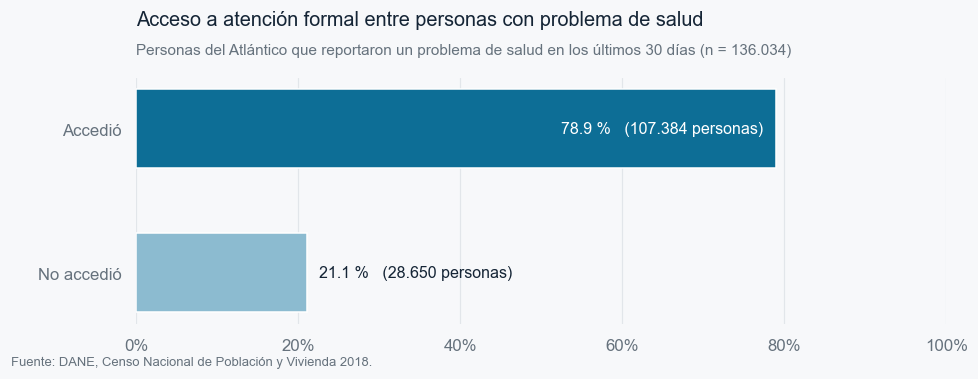

In [17]:
datos = distribucion_acceso.reindex(orden_acceso)

fig, ax = plt.subplots(figsize=(9.5, 2.9))
barras = ax.barh(datos.index, datos["% del total"],
                 color=[colores_acceso[i] for i in datos.index], height=0.55)
ax.invert_yaxis()

for barra, (pct, n) in zip(barras, datos[["% del total", "n"]].values):
    texto = f"{pct:.1f} %   ({n:,.0f} personas)".replace(",", ".")
    dentro = pct > 55
    ax.text(pct - 1.5 if dentro else pct + 1.5, barra.get_y() + barra.get_height()/2,
            texto, va="center", ha="right" if dentro else "left",
            fontsize=10.5, color="white" if dentro else TINTA,
            fontweight="normal")

ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
ax.set_xlabel("")
estilo(ax, "x",
       "Acceso a atención formal entre personas con problema de salud",
       f"Personas del Atlántico que reportaron un problema de salud en los últimos 30 días (n = {len(df_eda):,})".replace(",", "."))
guardar(fig, "01_distribucion_acceso")
plt.show()

En la ejecución verificada, 107.384 de 136.034 personas clasificables accedieron (78,94 %) y
28.650 no accedieron (21,06 %). Por tanto, más de la mitad del grupo analizado accedió;
aproximadamente una de cada cinco personas no lo hizo según la definición operativa. La tabla
siguiente muestra la acción principal declarada, que ayuda a interpretar esa última cifra.

In [18]:
detalle = (df_eda["P_QUEHIZO_PPAL"].map(etiquetas["P_QUEHIZO_PPAL"])
           .value_counts(dropna=False).rename("n").to_frame())
detalle["% del total"] = (detalle["n"] / len(df_eda) * 100).round(2)
detalle

,n,% del total
P_QUEHIZO_PPAL,,
Acudió a su entidad de seguridad social,99429,73.09
Se autorrecetó,14288,10.50
Acudió a un médico particular,9862,7.25
Usó remedios caseros,6011,4.42
No hizo nada,3271,2.40
Acudió al boticario o droguista,2954,2.17
Asistió a terapias alternativas,187,0.14
Acudió a otro médico de un grupo étnico,22,0.02
Acudió a autoridad indígena espiritual,10,0.01


La automedicación fue la acción principal de 14.288 personas, cerca de la mitad de las 28.650
clasificadas sin acceso. Otras 6.011 declararon remedios caseros y 3.271 no hicieron nada.
Además, 1.907 acudieron a su entidad de seguridad social y declararon no haber sido atendidas.
El censo registra acciones, pero no permite atribuir las demás situaciones de no acceso a
preferencias individuales, barreras de oferta o gravedad del problema.

In [19]:
for col, nombre in [("DIFICULTAD", "Dificultad funcional"), ("SEXO", "Sexo"), ("ZONA", "Zona")]:
    mostrar(resumen_categorico(df_eda[col]).rename_axis(col), nombre)

,n,% del total
DIFICULTAD,,
Sin dificultad funcional,111711,82.12
Con dificultad funcional,24323,17.88


,n,% del total
SEXO,,
Mujer,77963,57.31
Hombre,58071,42.69


,n,% del total
ZONA,,
Cabecera municipal,127790,93.94
Centro poblado,6160,4.53
Rural disperso,2084,1.53


In [20]:
edad_orden = list(etiquetas["P_EDADR"].values())
resumen_categorico(df_eda["EDAD_GRUPO"]).reindex(edad_orden)

,n,% del total
EDAD_GRUPO,,
0-4,12977,9.54
5-9,8400,6.17
10-14,6713,4.93
15-19,7158,5.26
20-24,7437,5.47
25-29,8203,6.03
30-34,8167,6.00
35-39,8982,6.60
40-44,8320,6.12


En la ejecución verificada, 93,94 % de la base analítica vivía en cabecera municipal, 57,31 % eran
mujeres y el grupo de 0 a 4 años representaba 9,54 %. Son distribuciones de quienes reportaron
un problema de salud y tuvieron acceso clasificable; no describen la composición de todo el
departamento ni prueban diferencias en la frecuencia de enfermedad entre grupos.

In [21]:
mostrar(resumen_categorico(df_eda["ESTRATO"]).sort_index().rename_axis("ESTRATO"), "Estrato")
mostrar(resumen_categorico(df_eda["NIVEL_EDUCATIVO"]).rename_axis("NIVEL_EDUCATIVO"), "Nivel educativo")
mostrar(resumen_categorico(df_eda["GRUPO_ETNICO"]).rename_axis("GRUPO_ETNICO"), "Reconocimiento étnico")

,n,% del total
ESTRATO,,
Estrato 1,62066,45.63
Estrato 2,37150,27.31
Estrato 3,21124,15.53
Estrato 4,8862,6.51
Estrato 5,2425,1.78
Estrato 6,1608,1.18
Sin dato,1554,1.14
Sin estrato,1245,0.92


,n,% del total
NIVEL_EDUCATIVO,,
Básica primaria,31863,23.42
Media académica,26526,19.50
Básica secundaria,17445,12.82
Universitario,15838,11.64
Sin dato,13666,10.05
Técnica o tecnológica,13471,9.90
Ninguno,6431,4.73
Posgrado,4369,3.21
Preescolar,2994,2.20


,n,% del total
GRUPO_ETNICO,,
Ningún grupo étnico,121330,89.19
"Negro(a), mulato(a), afrodescendiente",11766,8.65
Indígena,2578,1.90
Sin dato,267,0.20
Palenquero(a),43,0.03
Raizal,35,0.03
Gitano(a) o Rrom,15,0.01


Los estratos 1 y 2 reunieron 72,94 % de la base en la ejecución verificada. El 10,05 % no tenía
un nivel educativo registrado o aplicable. En reconocimiento étnico, 89,19 % no se identificó
con ninguno de los grupos listados y 8,65 % se reconoció como negro, mulato o afrodescendiente.
Las categorías con pocos registros se muestran en la descripción, pero se evitan comparaciones
de tasas de acceso que dependerían de muy pocos casos.

In [22]:
for variable, titulo in [
    ("P_PARENTESCOR", "Parentesco con la jefatura del hogar"),
    ("P_ALFABETA", "Alfabetismo"),
    ("PA_ASISTENCIA", "Asistencia escolar"),
    ("P_TRABAJO", "Actividad la semana anterior"),
    ("P_EST_CIVIL", "Estado civil"),
]:
    mostrar(resumen_categorico(df_eda[variable], etiquetas.get(variable)), titulo)

,n,% del total
P_PARENTESCOR,,
Jefe(a) del hogar,48007,35.29
Hijo(a) o hijastro(a),38570,28.35
Pareja,25097,18.45
Otro pariente,22773,16.74
Otro no pariente,1587,1.17


,n,% del total
P_ALFABETA,,
Sí sabe leer y escribir,114486,84.16
Sin dato,13267,9.75
No sabe leer y escribir,8281,6.09


,n,% del total
PA_ASISTENCIA,,
No asiste,96565,70.99
Sí asiste,26124,19.20
Sin dato,13345,9.81


,n,% del total
P_TRABAJO,,
Trabajó,39971,29.38
Oficios del hogar,29901,21.98
Sin dato,23242,17.09
Estudió,13800,10.14
"Vivió de jubilación, pensión o renta",6913,5.08
Otra situación,6582,4.84
Buscó trabajo,6027,4.43
No trabajó pero tenía empleo,4706,3.46
Incapacitado permanentemente,4154,3.05


,n,% del total
P_EST_CIVIL,,
Casado(a),34118,25.08
Soltero(a),29985,22.04
Unión libre,28997,21.32
Sin dato,21597,15.88
Viudo(a),8984,6.60
Separado(a) de unión libre,7343,5.40
Separado(a) de matrimonio,3921,2.88
Divorciado(a),1089,0.80


## Descripción univariada de las cantidades del hogar

Para las cuatro variables cuantitativas se informa el número de observaciones válidas, la media,
la mediana (percentil 50), la desviación estándar, mínimo, cuartiles y máximo. Son cantidades
del hogar repetidas para cada persona incluida: los resultados se ponderan implícitamente por
el número de personas elegibles en cada hogar y no describen el hogar típico del departamento.

In [23]:
cuantitativas = ["H_NRO_CUARTOS", "H_NRO_DORMIT", "HA_TOT_PER", "PERS_POR_CUARTO"]
resumen_cuant = df_eda[cuantitativas].describe().T
resumen_cuant = resumen_cuant.rename(columns={"count": "n válido", "mean": "media", "std": "desv. estándar",
                                      "min": "mínimo", "25%": "Q1", "50%": "mediana (P50)",
                                      "75%": "Q3", "max": "máximo"})
resumen_cuant["n faltante"] = len(df_eda) - resumen_cuant["n válido"]
resumen_cuant[["n válido", "media", "mediana (P50)", "desv. estándar",
              "mínimo", "Q1", "Q3", "máximo", "n faltante"]].round(3)

,n válido,media,mediana (P50),desv. estándar,mínimo,Q1,Q3,máximo,n faltante
H_NRO_CUARTOS,135945.0,3.589,4.00,1.157,1.00,3.000,4.000,20.0,89.0
H_NRO_DORMIT,135945.0,2.396,2.00,0.937,1.00,2.000,3.000,20.0,89.0
HA_TOT_PER,136034.0,4.456,4.00,2.147,1.00,3.000,5.000,30.0,0.0
PERS_POR_CUARTO,135945.0,1.366,1.25,0.847,0.05,0.833,1.667,17.0,89.0


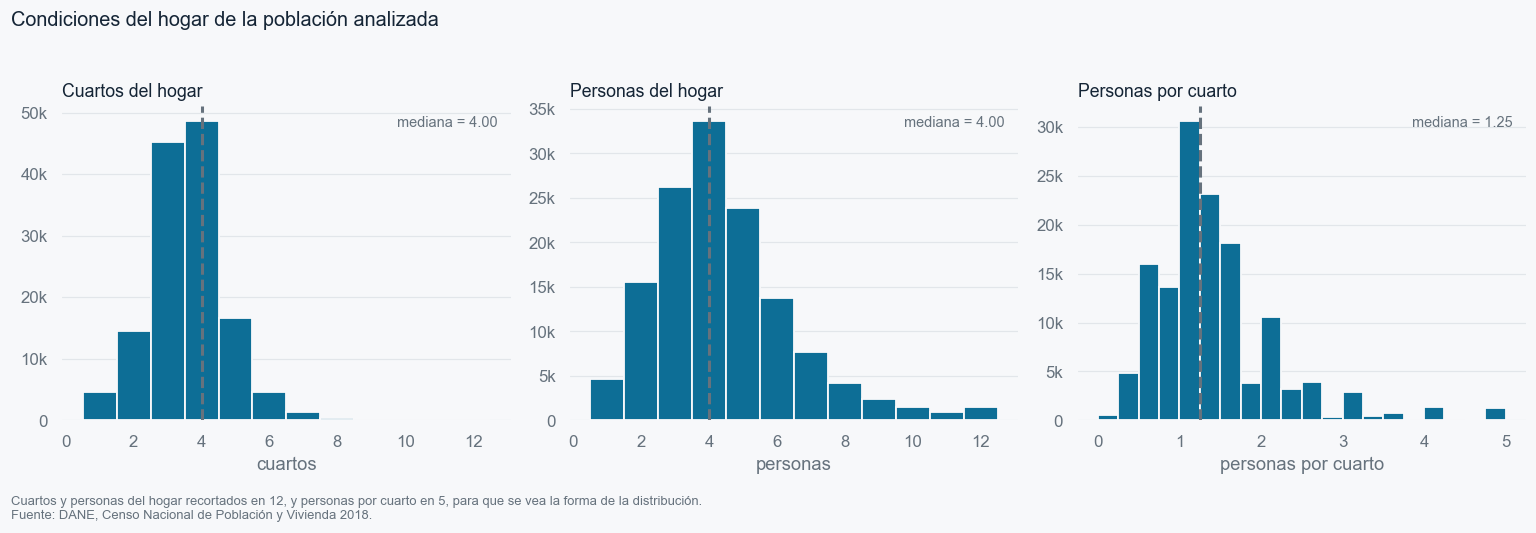

In [24]:
nombres = {
    "H_NRO_CUARTOS": "Cuartos del hogar",
    "HA_TOT_PER": "Personas del hogar",
    "PERS_POR_CUARTO": "Personas por cuarto",
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

for ax, (col, titulo) in zip(axes, nombres.items()):
    datos = df_eda[col].dropna()
    if col == "PERS_POR_CUARTO":
        bins = np.arange(0, 5.25, 0.25)
        datos = datos.clip(upper=5)
    else:
        bins = np.arange(0.5, min(datos.max(), 12) + 1.5, 1)
        datos = datos.clip(upper=12)
    ax.hist(datos, bins=bins, color=AZUL, edgecolor=FONDO, linewidth=1.2)
    ax.axvline(datos.median(), color=TINTA2, linewidth=2, linestyle="--")
    ax.text(0.97, 0.97, f"mediana = {df_eda[col].median():.2f}", transform=ax.transAxes,
            color=TINTA2, fontsize=9.5, va="top", ha="right")
    ax.set_title(titulo, loc="left", fontsize=11.5, color=TINTA)
    ax.set_ylabel("")
    estilo(ax, "y", nota=None)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v/1000:.0f}k" if v >= 1000 else f"{v:.0f}"))

axes[0].set_xlabel("cuartos")
axes[1].set_xlabel("personas")
axes[2].set_xlabel("personas por cuarto")
fig.suptitle("Condiciones del hogar de la población analizada", x=0.005, ha="left",
             fontsize=13, color=TINTA, y=1.04)
fig.text(0.005, -0.06, "Cuartos y personas del hogar recortados en 12, y personas por cuarto en 5, para que se vea la forma de la distribución.\n" + FUENTE,
         fontsize=8.5, color=TINTA2)
fig.tight_layout()
guardar(fig, "02_histogramas_cuantitativas")
plt.show()

En la ejecución verificada, la mediana fue 4 cuartos, 4 personas y 1,25 personas por cuarto.
La mediana es el percentil 50: la mitad de las observaciones válidas queda en ese valor o por
debajo. La media de personas por cuarto fue 1,37 y el máximo 17, lo que muestra una cola derecha.
El histograma recorta el eje horizontal para ver la forma central; la tabla conserva los máximos
sin recortar.

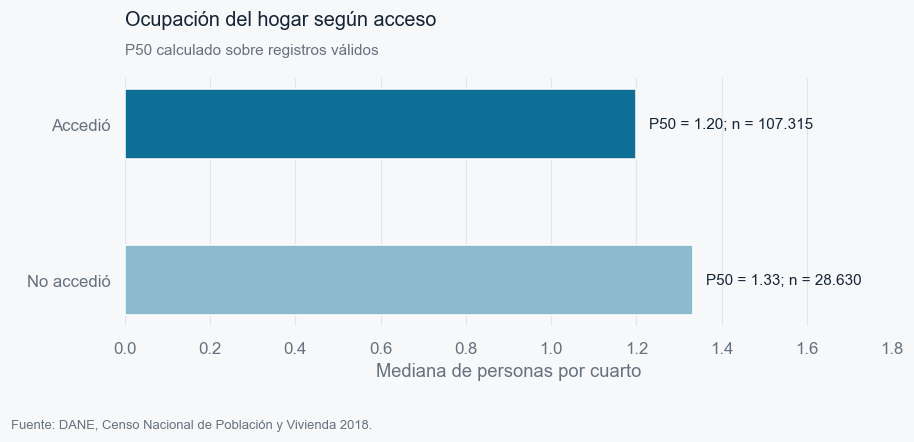

,n válido,media,desv. estándar,mínimo,Q1,mediana (P50),Q3,máximo
ACCESO,,,,,,,,
Accedió,107315.0,1.332,0.807,0.050,0.8,1.200,1.667,17.0
No accedió,28630.0,1.497,0.972,0.083,1.0,1.333,1.750,17.0


In [25]:
resumen_ocupacion = (df_eda.groupby("ACCESO")["PERS_POR_CUARTO"]
                     .agg(n="count", mediana="median").reindex(orden_acceso))
fig, ax = plt.subplots(figsize=(9, 3.7))
for y, (grupo, fila) in enumerate(resumen_ocupacion.iterrows()):
    mediana, n = fila["mediana"], int(fila["n"])
    ax.barh(y, mediana, color=colores_acceso[grupo], height=0.45)
    ax.text(mediana + 0.03, y,
            f"P50 = {mediana:.2f}; n = {n:,.0f}".replace(",", "."),
            va="center", fontsize=10)
ax.set_yticks(range(len(orden_acceso)), orden_acceso)
ax.invert_yaxis()
ax.set_xlim(0, max(1.8, resumen_ocupacion["mediana"].max() + 0.4))
ax.set_xlabel("Mediana de personas por cuarto")
estilo(ax, "x", "Ocupación del hogar según acceso",
       "P50 calculado sobre registros válidos", nota=None)
fig.subplots_adjust(bottom=0.27)
fig.text(0.01, 0.02, FUENTE, fontsize=8.5, color=TINTA2)
guardar(fig, "03_mediana_hogar_acceso")
plt.show()

def descriptivos_por_acceso(col):
    return (df_eda.groupby("ACCESO")[col].describe()
            .rename(columns={"count": "n válido", "mean": "media", "std": "desv. estándar",
                             "min": "mínimo", "25%": "Q1", "50%": "mediana (P50)",
                             "75%": "Q3", "max": "máximo"})
            .reindex(orden_acceso).round(3))

mostrar(descriptivos_por_acceso("PERS_POR_CUARTO"), "Personas por cuarto según acceso")


La ejecución verificada mostró una mediana de 1,20 personas por cuarto entre quienes accedieron y
1,33 entre quienes no accedieron. La mediana es el percentil 50, pero por sí sola no describe
toda la distribución. La tabla complementaria presenta el número de observaciones válidas,
media, desviación estándar, extremos y cuartiles de cada grupo. Para comparar el acceso dentro
de niveles de ocupación se usa más adelante una tabla de tasas por tramos. La diferencia
observada no demuestra un efecto del hacinamiento.

## Acceso según las variables explicativas

El análisis bivariado se organiza alrededor de `ACCESO_FORMAL_SALUD`. En cada tabla se presentan
el número de registros con dato válido, los conteos de acceso y no acceso, y sus porcentajes
dentro de cada grupo. Así se comparan tasas con denominadores explícitos. Las diferencias son
descriptivas; no implican causalidad ni significación estadística.

In [26]:
orden_dificultad = ["Con dificultad funcional", "Sin dificultad funcional"]
tabla_dificultad = tabla_acceso_por(df_eda["DIFICULTAD"], orden_dificultad)
pct_dificultad = tabla_dificultad[["Accedió: % del grupo", "No accedió: % del grupo"]].copy()
pct_dificultad.columns = orden_acceso
mostrar(tabla_dificultad, "Acceso según dificultad funcional")

,n válido,Accedió: n,Accedió: % del grupo,No accedió: n,No accedió: % del grupo
grupo,,,,,
Con dificultad funcional,24323,20659,84.94,3664,15.06
Sin dificultad funcional,111711,86725,77.63,24986,22.37


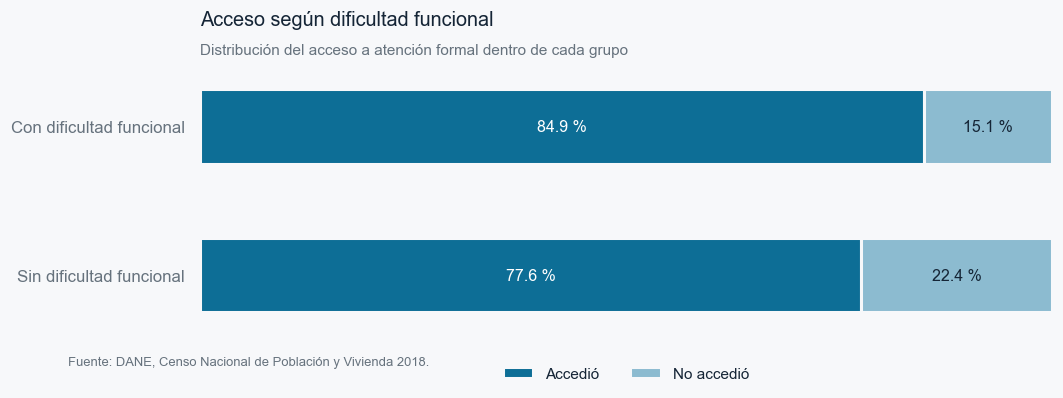

In [27]:
fig, ax = plt.subplots(figsize=(10, 2.9))

izquierda = np.zeros(len(pct_dificultad))
for categoria in orden_acceso:
    valores = pct_dificultad[categoria].values
    ax.barh(pct_dificultad.index, valores, left=izquierda, height=0.5,
            color=colores_acceso[categoria], label=categoria,
            edgecolor=FONDO, linewidth=2)
    for y, (v, x0) in enumerate(zip(valores, izquierda)):
        ax.text(x0 + v/2, y, f"{v:.1f} %", ha="center", va="center",
                color="white" if categoria == "Accedió" else TINTA,
                fontsize=10.5, fontweight="normal")
    izquierda += valores

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xticks([])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2,
          frameon=False, fontsize=10)
estilo(ax, None,
       "Acceso según dificultad funcional",
       "Distribución del acceso a atención formal dentro de cada grupo")
guardar(fig, "04_acceso_por_dificultad")
plt.show()

En la ejecución verificada, accedió 84,94 % de quienes declararon dificultad funcional frente a
77,63 % de quienes no la declararon: una diferencia descriptiva cercana a 7,3 puntos porcentuales.
Los grupos tienen estructuras de edad distintas. Por eso se muestran las tasas por edad y una
comparación estandarizada antes de interpretar la cifra agregada.

In [28]:
edad_orden = list(etiquetas["P_EDADR"].values())

pct_edad = (df_eda.pivot_table(index="EDAD_GRUPO", columns="DIFICULTAD",
                               values="ACCESO_FORMAL_SALUD", aggfunc="mean")
            .reindex(edad_orden) * 100)
n_edad = (df_eda.pivot_table(index="EDAD_GRUPO", columns="DIFICULTAD",
                             values="ACCESO_FORMAL_SALUD", aggfunc="size")
          .reindex(edad_orden))

tabla_edad_dificultad = (df_eda.groupby(["EDAD_GRUPO", "DIFICULTAD"])["ACCESO_FORMAL_SALUD"]
                          .agg(n="size", acceso_n="sum", acceso_pct="mean"))
tabla_edad_dificultad["no_acceso_n"] = tabla_edad_dificultad["n"] - tabla_edad_dificultad["acceso_n"]
tabla_edad_dificultad["acceso_pct"] = (tabla_edad_dificultad["acceso_pct"] * 100).round(2)
tabla_edad_dificultad["no_acceso_pct"] = 100 - tabla_edad_dificultad["acceso_pct"]
mostrar(tabla_edad_dificultad.reindex(edad_orden, level=0), "Acceso por edad y dificultad funcional")

n  acceso_n  acceso_pct  no_acceso_n  no_acceso_pct
EDAD_GRUPO DIFICULTAD                                                                       
0-4        Con dificultad funcional    405       355       87.65           50          12.35
           Sin dificultad funcional  12572     10324       82.12         2248          17.88
5-9        Con dificultad funcional    608       493       81.09          115          18.91
           Sin dificultad funcional   7792      5623       72.16         2169          27.84
10-14      Con dificultad funcional    650       529       81.38          121          18.62
           Sin dificultad funcional   6063      4261       70.28         1802          29.72
15-19      Con dificultad funcional    741       565       76.25          176          23.75
           Sin dificultad funcional   6417      4463       69.55         1954          30.45
20-24      Con dificultad funcional    634       482       76.03          152          23.97
           Sin dificultad funcional   6803      4790       70.41         2013          29.59
25-29      Con dificultad funcional    757       604       79.79          153          20.21
           Sin dificultad funcional   7446      5407       72.62         2039          27.38
30-34      Con dificultad funcional    760       596       78.42          164          21.58
           Sin dificultad funcional   7407      5438       73.42         1969          26.58
35-39      Con dificultad funcional    978       769       78.63          209          21.37
           Sin dificultad funcional   8004      5899        73.7         2105           26.3
40-44      Con dificultad funcional   1284       999        77.8          285           22.2
           Sin dificultad funcional   7036      5286       75.13         1750          24.87
45-49      Con dificultad funcional   1752      1413       80.65          339          19.35
           Sin dificultad funcional   7288      5601       76.85         1687          23.15
50-54      Con dificultad funcional   2133      1723       80.78          410          19.22
           Sin dificultad funcional   7652      6093       79.63         1559          20.37
55-59      Con dificultad funcional   2391      2007       83.94          384          16.06
           Sin dificultad funcional   7122      5886       82.65         1236          17.35
60-64      Con dificultad funcional   2199      1877       85.36          322          14.64
           Sin dificultad funcional   5966      5051       84.66          915          15.34
65-69      Con dificultad funcional   2097      1877       89.51          220          10.49
           Sin dificultad funcional   4951      4298       86.81          653          13.19
70-74      Con dificultad funcional   1818      1645       90.48          173           9.52
           Sin dificultad funcional   3599      3190       88.64          409          11.36
75-79      Con dificultad funcional   1771      1625       91.76          146           8.24
           Sin dificultad funcional   2555      2323       90.92          232           9.08
80-84      Con dificultad funcional   1558      1423       91.34          135           8.66
           Sin dificultad funcional   1742      1602       91.96          140           8.04
85-89      Con dificultad funcional   1047       986       94.17           61           5.83
           Sin dificultad funcional    880       813       92.39           67           7.61
90-94      Con dificultad funcional    519       481       92.68           38           7.32
           Sin dificultad funcional    313       283       90.42           30           9.58
95-99      Con dificultad funcional    186       175       94.09           11           5.91
           Sin dificultad funcional     80        74        92.5            6            7.5
100+       Con dificultad funcional     35        35       100.0            0            0.0
           Sin dificultad funcional     23

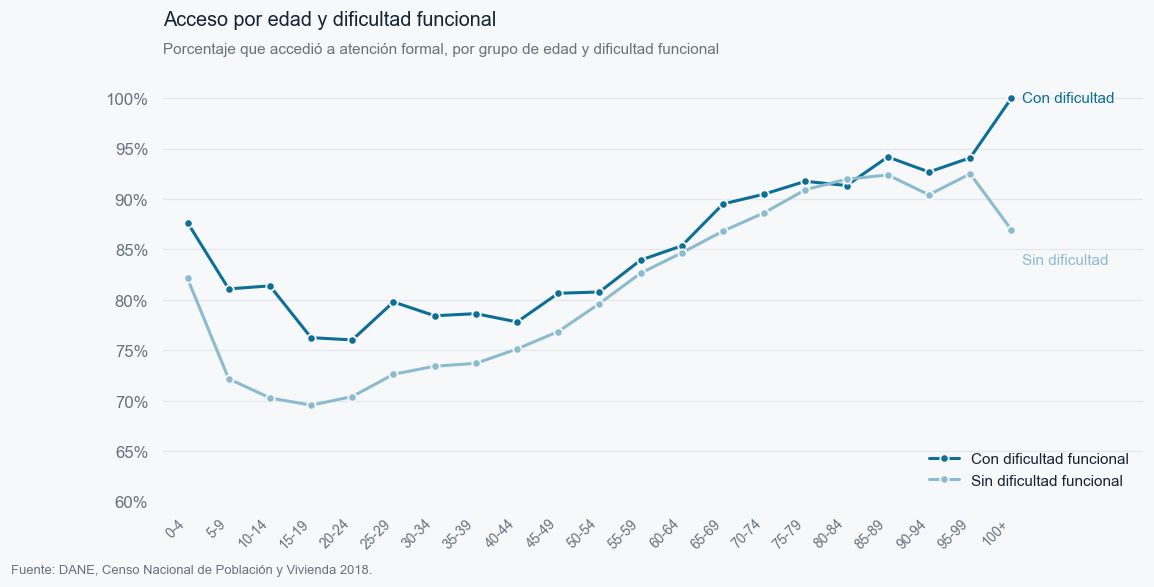

In [29]:
colores_dif = {"Con dificultad funcional": AZUL, "Sin dificultad funcional": AZUL_CLARO}

fig, ax = plt.subplots(figsize=(11.5, 5))
x = np.arange(len(edad_orden))

for grupo in orden_dificultad:
    ax.plot(x, pct_edad[grupo], color=colores_dif[grupo], linewidth=2,
            marker="o", markersize=5.5, markeredgecolor=FONDO,
            markeredgewidth=1.2, label=grupo)

ax.text(x[-1] + 0.25, pct_edad[orden_dificultad[0]].iloc[-1], "Con dificultad",
        color=colores_dif[orden_dificultad[0]], fontsize=10, va="center")
ax.text(x[-1] + 0.25, pct_edad[orden_dificultad[1]].iloc[-1] - 3, "Sin dificultad",
        color=colores_dif[orden_dificultad[1]], fontsize=10, va="center")

ax.set_xticks(x); ax.set_xticklabels(edad_orden, rotation=45, ha="right", fontsize=9)
ax.set_ylim(60, 102)
ax.set_xlim(-0.6, len(x) + 2.2)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
ax.legend(frameon=False, loc="lower right", fontsize=10)
estilo(ax, "y",
       "Acceso por edad y dificultad funcional",
       "Porcentaje que accedió a atención formal, por grupo de edad y dificultad funcional")
guardar(fig, "05_acceso_edad_dificultad")
plt.show()

En la ejecución verificada, el acceso fue menor entre los grupos de 10 a 24 años y aumentó desde
la adultez media hacia las edades avanzadas. El grupo de 0 a 4 años no siguió esa secuencia:
tuvo tasas mayores. La diferencia por dificultad funcional fue más visible en edades jóvenes
y se estrechó desde los 50 años, aunque no desapareció en todos los grupos. En 100 años o más,
los subgrupos tenían 35 y 23 personas; sus porcentajes cambian mucho con un solo registro.
Estos patrones no permiten separar la dificultad funcional de otras características asociadas
a la edad.

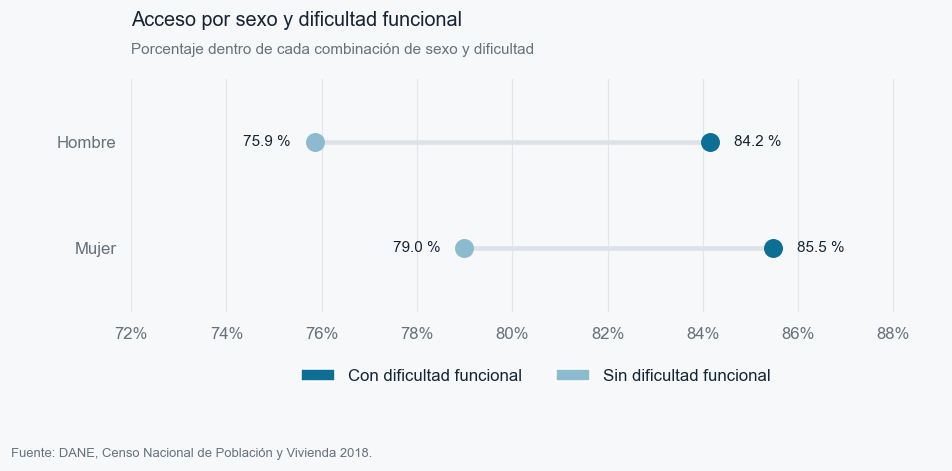

n  acceso_n  acceso_pct  no_acceso_n  no_acceso_pct
SEXO   DIFICULTAD                                                                       
Hombre Con dificultad funcional   9896      8328       84.16         1568          15.84
       Sin dificultad funcional  48175     36541       75.85        11634          24.15
Mujer  Con dificultad funcional  14427     12331       85.47         2096          14.53
       Sin dificultad funcional  63536     50184       78.99        13352          21.01

In [30]:
pct_sexo = (df_eda.pivot_table(index="SEXO", columns="DIFICULTAD",
                               values="ACCESO_FORMAL_SALUD", aggfunc="mean") * 100)
n_sexo = df_eda.pivot_table(index="SEXO", columns="DIFICULTAD",
                            values="ACCESO_FORMAL_SALUD", aggfunc="size")

fig, ax = plt.subplots(figsize=(9.5, 4.0))
for y, sexo in enumerate(pct_sexo.index):
    v_con = pct_sexo.loc[sexo, orden_dificultad[0]]
    v_sin = pct_sexo.loc[sexo, orden_dificultad[1]]
    ax.plot([v_sin, v_con], [y, y], color=GRID, linewidth=3, zorder=1)
    ax.scatter(v_sin, y, s=130, color=colores_dif[orden_dificultad[1]], zorder=2)
    ax.scatter(v_con, y, s=130, color=colores_dif[orden_dificultad[0]], zorder=2)
    ax.text(v_sin - 0.5, y, f"{v_sin:.1f} %", ha="right", va="center", fontsize=10)
    ax.text(v_con + 0.5, y, f"{v_con:.1f} %", ha="left", va="center", fontsize=10)
ax.set_yticks(range(len(pct_sexo)), pct_sexo.index)
ax.set_xlim(72, 89)
ax.set_ylim(-0.6, len(pct_sexo) - 0.4)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=colores_dif[g], label=g) for g in orden_dificultad],
          ncol=2, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18))
estilo(ax, "x", "Acceso por sexo y dificultad funcional",
       "Porcentaje dentro de cada combinación de sexo y dificultad", nota=None)
fig.subplots_adjust(bottom=0.35)
fig.text(0.01, 0.02, FUENTE, fontsize=8.5, color=TINTA2)
guardar(fig, "06_acceso_sexo_dificultad")
plt.show()

tabla_sexo = (df_eda.groupby(["SEXO", "DIFICULTAD"])["ACCESO_FORMAL_SALUD"]
              .agg(n="size", acceso_n="sum", acceso_pct=lambda s: round(s.mean() * 100, 2)))
tabla_sexo["no_acceso_n"] = tabla_sexo["n"] - tabla_sexo["acceso_n"]
tabla_sexo["no_acceso_pct"] = 100 - tabla_sexo["acceso_pct"]
mostrar(tabla_sexo, "Acceso por sexo y dificultad funcional")


En la ejecución verificada, entre quienes declararon dificultad funcional accedieron 85,47 % de
las mujeres y 84,16 % de los hombres; sin dificultad, 78,99 % y 75,85 %, respectivamente.
Son diferencias de 1,31 y 3,14 puntos dentro de cada grupo de dificultad. Las tasas se
calculan con sus propios denominadores y no establecen un efecto independiente del sexo.

,n válido,Accedió: n,Accedió: % del grupo,No accedió: n,No accedió: % del grupo
grupo,,,,,
Sin estrato,1245,852,68.43,393,31.57
Estrato 1,62066,48342,77.89,13724,22.11
Estrato 2,37150,29193,78.58,7957,21.42
Estrato 3,21124,16749,79.29,4375,20.71
Estrato 4,8862,7613,85.91,1249,14.09
Estrato 5,2425,2084,85.94,341,14.06
Estrato 6,1608,1408,87.56,200,12.44


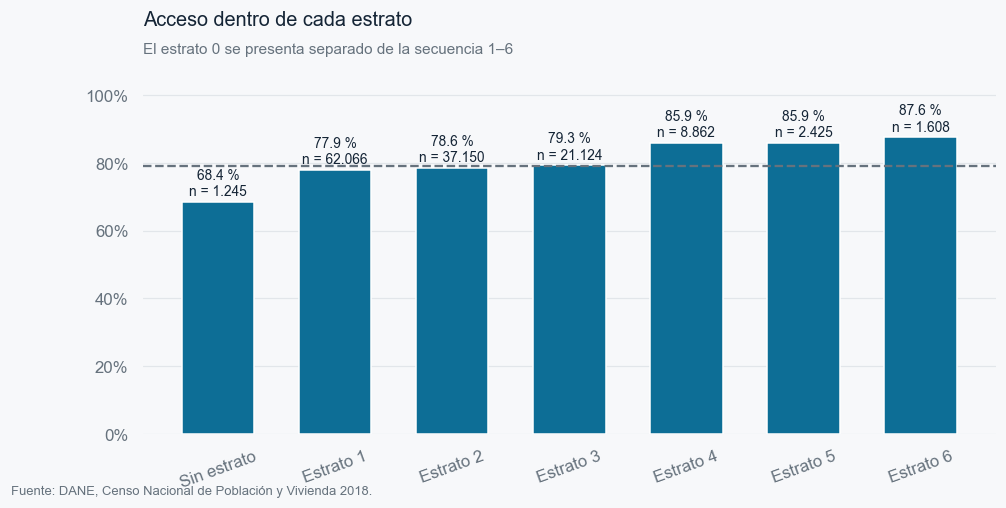

In [31]:
orden_estrato = ["Sin estrato"] + [f"Estrato {i}" for i in range(1, 7)]
tabla_estrato = tabla_acceso_por(df_eda["ESTRATO"], orden_estrato)
mostrar(tabla_estrato, "Acceso por estrato de la vivienda")
acceso_estrato = tabla_estrato[["n válido", "Accedió: % del grupo"]].rename(
    columns={"n válido": "n", "Accedió: % del grupo": "porcentaje"})
promedio_general = df_eda["ACCESO_FORMAL_SALUD"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 4.2))
barras = ax.bar(acceso_estrato.index, acceso_estrato["porcentaje"], color=AZUL, width=0.62)
ax.axhline(promedio_general, color=TINTA2, linewidth=1.5, linestyle="--")
for barra, pct, n in zip(barras, acceso_estrato["porcentaje"], acceso_estrato["n"]):
    ax.text(barra.get_x() + barra.get_width()/2, pct + 1,
            f"{pct:.1f} %\nn = {n:,.0f}".replace(",", "."),
            ha="center", va="bottom", fontsize=9, color=TINTA)
ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
ax.tick_params(axis="x", labelrotation=20)
estilo(ax, "y", "Acceso dentro de cada estrato",
       "El estrato 0 se presenta separado de la secuencia 1–6")
guardar(fig, "07_acceso_por_estrato")
plt.show()

En la ejecución verificada, el acceso observado fue 77,89 %, 78,58 % y 79,29 % en los estratos
1, 2 y 3; subió a 85,91 % en el 4 y luego fue 85,94 % y 87,56 % en 5 y 6.
La serie 1–6 no muestra aumentos iguales de un estrato al siguiente. El grupo sin estrato
(n = 1.245) tuvo 68,43 % y se presenta aparte porque 0 no representa un nivel inferior en
la misma escala. Un boxplot de la respuesta binaria frente al código ordinal del estrato
concentraría las cajas en 0 y 1, por lo que el gráfico de tasas por estrato permite evaluar
mejor el acceso dentro de cada categoría. Las diferencias son descriptivas y podrían reflejar
otras características de sus residentes.

In [32]:
tramos = pd.cut(df_eda["PERS_POR_CUARTO"], [0, 1, 1.5, 2, 3, np.inf],
                labels=["Hasta 1", "1 a 1,5", "1,5 a 2", "2 a 3", "Más de 3"])
tabla_ocupacion = tabla_acceso_por(tramos, list(tramos.cat.categories))
mostrar(tabla_ocupacion, "Acceso según personas por cuarto")

,n válido,Accedió: n,Accedió: % del grupo,No accedió: n,No accedió: % del grupo
grupo,,,,,
Hasta 1,63125,51734,81.95,11391,18.05
"1 a 1,5",34900,27213,77.97,7687,22.03
"1,5 a 2",22937,17388,75.81,5549,24.19
2 a 3,10755,8029,74.65,2726,25.35
Más de 3,4228,2951,69.80,1277,30.20


En la ejecución verificada, la tasa de acceso fue 81,95 % entre quienes vivían con hasta una
persona por cuarto y 69,80 % con más de tres. Las tasas descendieron en cada tramo intermedio,
con denominadores que van de 4.228 a 63.125 personas. Los tramos facilitan la comparación,
pero la agrupación y las características de los hogares pueden influir en el patrón observado.

## Acceso territorial

La clase territorial y el municipio son dos formas de describir la variación espacial de la
misma respuesta. Los porcentajes se calculan dentro de cada territorio. Se muestran los tamaños
porque municipios con pocos registros pueden cambiar notablemente de tasa con pocos casos.

In [33]:
orden_zona = ["Cabecera municipal", "Centro poblado", "Rural disperso"]
tabla_zona = tabla_acceso_por(df_eda["ZONA"], orden_zona)
mostrar(tabla_zona, "Acceso según clase territorial")

,n válido,Accedió: n,Accedió: % del grupo,No accedió: n,No accedió: % del grupo
grupo,,,,,
Cabecera municipal,127790,101256,79.24,26534,20.76
Centro poblado,6160,4634,75.23,1526,24.77
Rural disperso,2084,1494,71.69,590,28.31


En la ejecución verificada, accedió 79,24 % de las 127.790 personas clasificables de cabecera,
75,23 % de las 6.160 de centro poblado y 71,69 % de las 2.084 de rural disperso.
La diferencia entre cabecera y rural disperso fue 7,55 puntos porcentuales. La comparación
describe a quienes reportaron un problema de salud en cada clase, no la cobertura de servicios
de todos sus residentes.

,n válido,Accedió: n,Accedió: % del grupo,No accedió: n,No accedió: % del grupo
grupo,,,,,
Malambo,8319,5920,71.16,2399,28.84
Palmar de Varela,1156,854,73.88,302,26.12
Repelón,3352,2581,77.00,771,23.00
Soledad,26672,20811,78.03,5861,21.97
Galapa,1484,1162,78.30,322,21.70
Barranquilla,62716,49313,78.63,13403,21.37
Juan de Acosta,758,598,78.89,160,21.11
Sabanalarga,7324,5790,79.06,1534,20.94
Luruaco,2507,1995,79.58,512,20.42


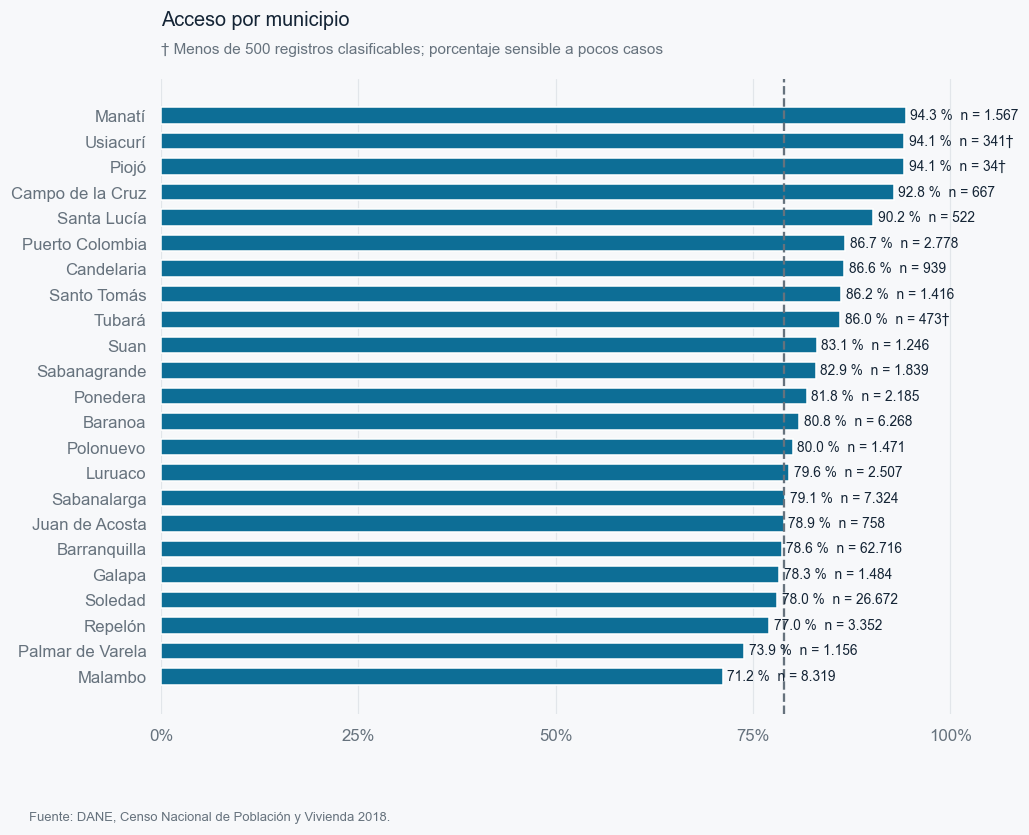

In [34]:
tabla_municipio = tabla_acceso_por(df_eda["MUNICIPIO"])
mostrar(tabla_municipio.sort_values("Accedió: % del grupo"), "Acceso por municipio")
acceso_mpio = tabla_municipio[["n válido", "Accedió: % del grupo"]].rename(
    columns={"n válido": "n", "Accedió: % del grupo": "porcentaje"}).sort_values("porcentaje")

fig, ax = plt.subplots(figsize=(10, 7.5))
barras = ax.barh(acceso_mpio.index, acceso_mpio["porcentaje"], color=AZUL, height=0.65)
ax.axvline(promedio_general, color=TINTA2, linewidth=1.5, linestyle="--")
for barra, (n, pct) in zip(barras, acceso_mpio.values):
    nota_n = "†" if n < 500 else ""
    ax.text(pct + 0.6, barra.get_y() + barra.get_height()/2,
            f"{pct:.1f} %  n = {n:,.0f}{nota_n}".replace(",", "."),
            va="center", fontsize=9, color=TINTA)
ax.set_xlim(0, 108)
ax.set_xticks([0, 25, 50, 75, 100])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
estilo(ax, "x", "Acceso por municipio",
       "† Menos de 500 registros clasificables; porcentaje sensible a pocos casos")
guardar(fig, "08_acceso_por_municipio")
plt.show()

### Mapa municipal

La geometría proviene de la capa oficial de municipios del MGN integrado 2018 del DANE,
guardada en `datos/mgn2018_municipios_atlantico.geojson`. Se une por `U_DPTO=08` y el código
municipal de tres dígitos. Antes de dibujar se comprueba que los 23 códigos son únicos y
corresponden a los de la base. Gris significa que el municipio no tiene registros
clasificables; una tasa válida de 0 % se colorea en el extremo inferior de la escala.
Cada municipio se identifica con su nombre al lado del mapa y una línea que señala su polígono;
esto evita que los nombres de los municipios pequeños se superpongan. La tabla contigua informa
el número de personas por municipio. El mapa muestra proporciones
entre quienes reportaron un problema de salud, sin ajuste por omisión censal.

,municipio MGN,n,accedieron,% acceso
código,,,,
001,BARRANQUILLA,62716,49313,78.63
078,BARANOA,6268,5067,80.84
137,CAMPO DE LA CRUZ,667,619,92.8
141,CANDELARIA,939,813,86.58
296,GALAPA,1484,1162,78.3
372,JUAN DE ACOSTA,758,598,78.89
421,LURUACO,2507,1995,79.58
433,MALAMBO,8319,5920,71.16
436,MANATÍ,1567,1478,94.32


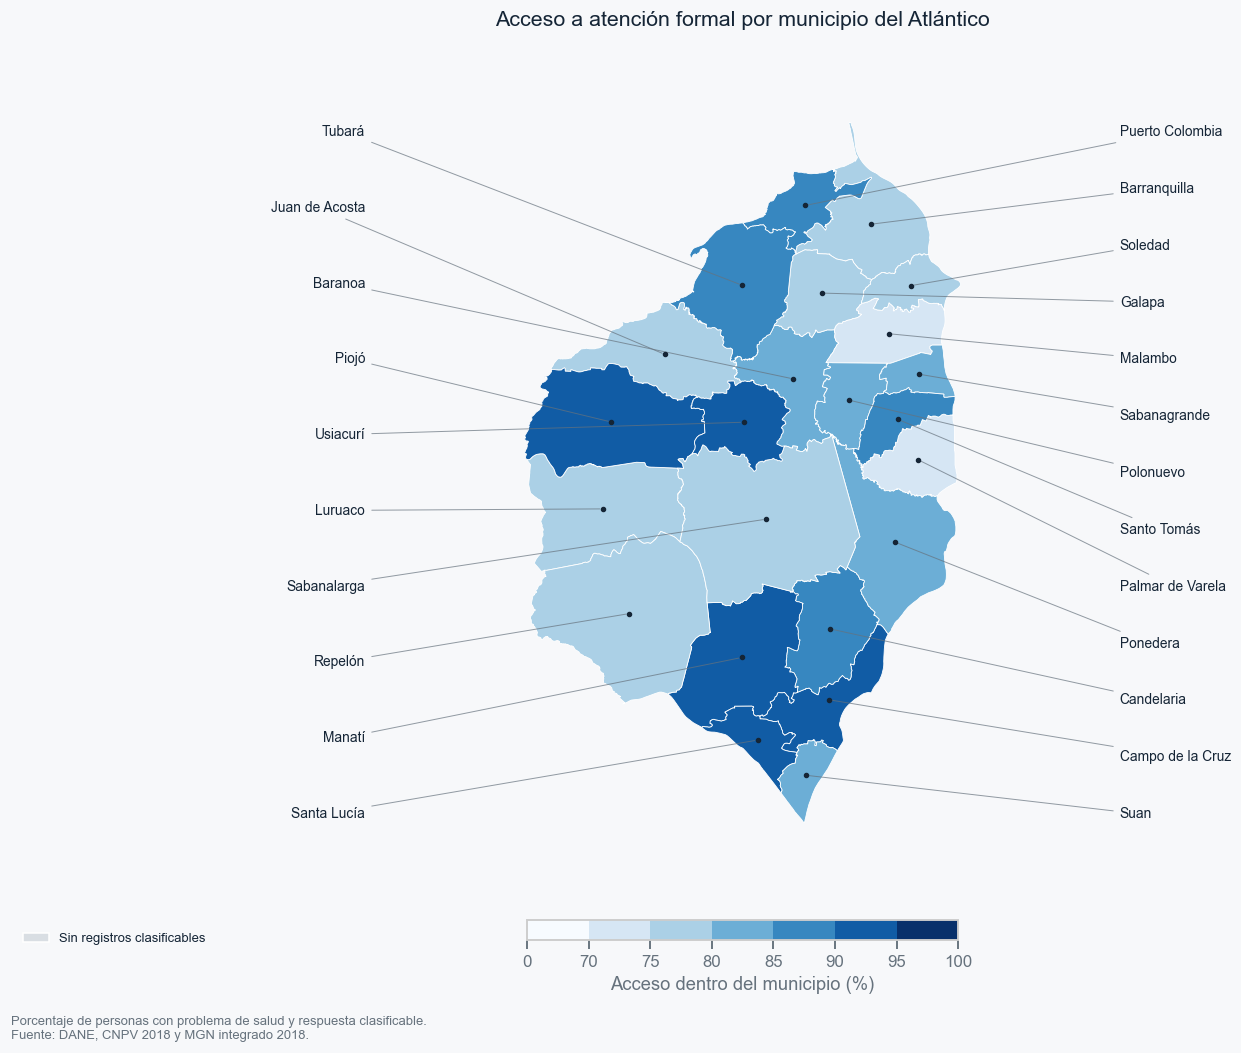

In [35]:
from matplotlib.patches import Polygon as MplPolygon, Patch
from matplotlib.colors import BoundaryNorm
from matplotlib.cm import ScalarMappable

geo_path = DATA_DIR / "mgn2018_municipios_atlantico.geojson"
geo = json.loads(geo_path.read_text(encoding="utf-8"))
features = geo["features"]
geo_codigos = [str(f["properties"]["MPIO_CCDGO"]).zfill(3) for f in features]
assert len(features) == 23 and len(set(geo_codigos)) == 23
assert set(geo_codigos) == set(municipios), "Los códigos MGN no coinciden con el diccionario municipal."
assert set(df_eda["U_MPIO"].dropna().astype(str).str.zfill(3)).issubset(set(geo_codigos))

resumen_mapa = (df_eda.assign(codigo=df_eda["U_MPIO"].astype(str).str.zfill(3))
                .groupby("codigo")["ACCESO_FORMAL_SALUD"]
                .agg(n="size", accedieron="sum", proporcion="mean"))
tabla_mapa = pd.DataFrame({
    "código": geo_codigos,
    "municipio MGN": [f["properties"]["MPIO_CNMBR"] for f in features],
}).set_index("código").join(resumen_mapa)
assert int(tabla_mapa["n"].fillna(0).sum()) == len(df_eda)
tabla_mapa["% acceso"] = (tabla_mapa["proporcion"] * 100).round(2)
mostrar(tabla_mapa[["municipio MGN", "n", "accedieron", "% acceso"]].sort_index(),
        "Unión del CNPV con la geometría municipal")

from matplotlib.path import Path as MplPath

def punto_interior(exterior):
    """Ubica la etiqueta dentro del polígono; si el centroide cae fuera, busca un punto interior."""
    puntos = np.asarray(exterior)
    x, y = puntos[:, 0], puntos[:, 1]
    cruz = x[:-1] * y[1:] - x[1:] * y[:-1]
    area = cruz.sum() / 2
    centro = np.array([((x[:-1] + x[1:]) * cruz).sum(),
                       ((y[:-1] + y[1:]) * cruz).sum()]) / (6 * area)
    poligono = MplPath(puntos)
    if poligono.contains_point(centro):
        return centro
    xx, yy = np.meshgrid(np.linspace(x.min(), x.max(), 35),
                         np.linspace(y.min(), y.max(), 35))
    candidatos = np.column_stack([xx.ravel(), yy.ravel()])
    internos = candidatos[poligono.contains_points(candidatos)]
    assert len(internos), "No se encontró un punto interior para un municipio."
    return internos[np.argmin(((internos - centro) ** 2).sum(axis=1))]

fig, ax = plt.subplots(figsize=(14, 10))
fig.subplots_adjust(left=0.28, right=0.72, top=0.88, bottom=0.18)
cmap = plt.get_cmap("Blues")
limites = [0, 70, 75, 80, 85, 90, 95, 100]
norm = BoundaryNorm(limites, cmap.N)
etiquetas_mapa = []
for f in features:
    codigo = str(f["properties"]["MPIO_CCDGO"]).zfill(3)
    pct = tabla_mapa.loc[codigo, "% acceso"]
    color = "#D9DEE3" if pd.isna(pct) else cmap(norm(pct))
    geom = f["geometry"]
    polygons = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
    for polygon in polygons:
        exterior = polygon[0]
        ax.add_patch(MplPolygon(exterior, closed=True, facecolor=color,
                                edgecolor="white", linewidth=0.55))
    centro = punto_interior(polygons[0][0])
    etiquetas_mapa.append((municipios[codigo], centro[0], centro[1]))
ax.autoscale_view()
ax.set_aspect("equal")
ax.set_axis_off()
for lado, seleccion in [
    ("izquierda", [e for e in etiquetas_mapa if e[1] < -74.92]),
    ("derecha", [e for e in etiquetas_mapa if e[1] >= -74.92]),
]:
    ordenadas = sorted(seleccion, key=lambda e: e[2], reverse=True)
    for (nombre, x, y), posicion_y in zip(ordenadas, np.linspace(0.84, 0.22, len(ordenadas))):
        ax.plot(x, y, marker="o", markersize=2.6, color=TINTA, zorder=5)
        ax.annotate(nombre, xy=(x, y), xycoords="data",
                    xytext=(0.255 if lado == "izquierda" else 0.745, posicion_y),
                    textcoords=fig.transFigure,
                    ha="right" if lado == "izquierda" else "left",
                    va="center", fontsize=9, color=TINTA,
                    arrowprops=dict(arrowstyle="-", color=TINTA2, lw=0.65, alpha=0.7))

cax = fig.add_axes([0.36, 0.105, 0.28, 0.018])
fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal",
             spacing="uniform", ticks=limites, label="Acceso dentro del municipio (%)")
fig.legend(handles=[Patch(facecolor="#D9DEE3", label="Sin registros clasificables")],
           loc="lower left", bbox_to_anchor=(0.025, 0.09), frameon=False, fontsize=8.5)
fig.suptitle("Acceso a atención formal por municipio del Atlántico", y=0.95, fontsize=14)
fig.text(0.025, 0.015, "Porcentaje de personas con problema de salud y respuesta clasificable.\n"
         "Fuente: DANE, CNPV 2018 y MGN integrado 2018.", fontsize=8.5, color=TINTA2)
guardar(fig, "09_mapa_acceso_municipal")
plt.show()

En la ejecución verificada, Malambo tuvo la tasa más baja (71,2 %, n = 8.319) y Manatí una de las
más altas (94,3 %, n = 1.567). Piojó alcanzó 94,1 %, pero correspondió a 32 de 34 personas;
un cambio de un caso equivale a 2,94 puntos porcentuales. Barranquilla y Soledad concentraron
65,7 % de la base analítica y registraron 78,6 % y 78,0 % de acceso, respectivamente.
La ubicación de la oferta sanitaria, los trámites o la gravedad no se midieron aquí; no se
atribuyen a esos factores las diferencias entre municipios.

## Magnitud descriptiva de las asociaciones

El CNPV es una operación censal y los microdatos empleados no son una muestra aleatoria de
personas enfermas de una población futura. Además, la respuesta se construye con una regla
analítica y hay cobertura y faltantes. Por estos motivos no se interpretan pruebas de hipótesis
ni valores p como evidencia de diferencias poblacionales. La V de Cramér resume únicamente la
intensidad de la asociación en las tablas observadas; un valor pequeño puede coexistir con
diferencias descriptivas visibles en grupos concretos.

In [36]:
def v_cramer_descriptiva(tabla):
    observada = tabla.to_numpy(dtype=float)
    n = observada.sum()
    esperada = np.outer(observada.sum(axis=1), observada.sum(axis=0)) / n
    chi2 = ((observada - esperada) ** 2 / esperada).sum()
    return float(np.sqrt(chi2 / (n * (min(observada.shape) - 1))))

asociaciones = []
for col, nombre in [("DIFICULTAD", "Dificultad funcional"), ("SEXO", "Sexo"),
                    ("ZONA", "Clase territorial"), ("ESTRATO", "Estrato"),
                    ("EDAD_GRUPO", "Grupo de edad"), ("MUNICIPIO", "Municipio")]:
    t = pd.crosstab(df_eda[col], df_eda["ACCESO"])
    asociaciones.append({"variable": nombre, "n válido": int(t.to_numpy().sum()),
                         "V de Cramér": round(v_cramer_descriptiva(t), 4)})
pd.DataFrame(asociaciones).sort_values("V de Cramér", ascending=False)

,variable,n válido,V de Cramér
4,Grupo de edad,136034,0.1630
5,Municipio,136034,0.0851
0,Dificultad funcional,136034,0.0686
3,Estrato,134480,0.0629
1,Sexo,136034,0.0354
2,Clase territorial,136034,0.0302


En la ejecución verificada, la V de Cramér fue 0,163 para grupo de edad, 0,085 para municipio y
menor de 0,07 para las demás variables consideradas. Esto indica asociaciones marginales
modestas en las tablas observadas; no mide capacidad predictiva individual ni ajusta por
variables relacionadas. La comparación de dificultad funcional se complementa con una
estandarización directa por edad.

### Estandarización por edad

Se aplican las tasas de acceso de cada grupo de dificultad en cada tramo de edad a una misma
estructura de edades: la de toda la base clasificable. Se informan las tasas crudas y
estandarizadas, siempre como comparaciones descriptivas. Todos los tramos necesitan observaciones
en ambos grupos; la celda siguiente comprueba esa condición.

In [37]:
# Composición por edad de cada grupo
composicion = (pd.crosstab(df_eda["EDAD_GRUPO"], df_eda["DIFICULTAD"], normalize="columns")
               .reindex(edad_orden) * 100).round(2)

mostrar((df_eda.assign(mayor_60=df_eda["P_EDADR"] >= 13)
         .groupby("DIFICULTAD")["mayor_60"].mean() * 100).round(2)
        .rename("porcentaje").to_frame(),
        "Porcentaje de 60 años o más en cada grupo")

# Estandarización directa: tasa por edad ponderada por la estructura de edad de toda la base
tasas = df_eda.pivot_table(index="P_EDADR", columns="DIFICULTAD",
                           values="ACCESO_FORMAL_SALUD", aggfunc="mean")
pesos = df_eda["P_EDADR"].value_counts(normalize=True).sort_index()
assert tasas.notna().all().all(), "Hay grupos de edad sin datos en una categoría de dificultad."
estandarizado = (tasas.mul(pesos, axis=0).sum() * 100).astype(float)

crudo = (df_eda.groupby("DIFICULTAD")["ACCESO_FORMAL_SALUD"].mean() * 100).astype(float)

comparacion = pd.DataFrame({
    "% acceso crudo": crudo.round(2),
    "% acceso estandarizado por edad": estandarizado.round(2),
}).reindex(orden_dificultad)

comparacion.loc["Diferencia (con − sin)"] = [
    round(crudo[orden_dificultad[0]] - crudo[orden_dificultad[1]], 2),
    round(estandarizado[orden_dificultad[0]] - estandarizado[orden_dificultad[1]], 2),
]
comparacion

,porcentaje
DIFICULTAD,
Con dificultad funcional,46.17
Sin dificultad funcional,18.00


,% acceso crudo,% acceso estandarizado por edad
DIFICULTAD,,
Con dificultad funcional,84.94,82.69
Sin dificultad funcional,77.63,78.44
Diferencia (con − sin),7.30,4.25


En la ejecución verificada, 46,17 % de quienes declararon dificultad funcional tenía 60 años o
más, frente a 18,00 % entre quienes no la declararon. La diferencia cruda de acceso fue
7,30 puntos porcentuales y la estandarizada por edad, 4,25. La composición por edad explica
parte de la discrepancia entre las tasas agregadas; los 4,25 puntos restantes no deben
interpretarse como efecto causal de la dificultad funcional, porque pueden intervenir otros
factores no controlados.

## Hallazgos, límites y conclusión

En la ejecución verificada, 78,94 % de las 136.034 personas clasificables accedió a
atención formal según la definición del proyecto. La mediana de personas por cuarto fue 1,25;
como percentil 50, divide las observaciones válidas en dos mitades alrededor de ese valor.
El acceso mostró tasas distintas por edad, dificultad funcional, sexo, ocupación del hogar,
estrato y territorio. La diferencia por dificultad se redujo de 7,30 a 4,25 puntos al
estandarizar por edad. El acceso entre estratos 1–3 fue próximo al 78–79 %, con un aumento
visible en el 4; no se presume un incremento uniforme por nivel. Entre municipios, las
diferencias deben leerse junto al número de registros de cada uno.

El resultado está condicionado por la pregunta sobre un problema de salud en los 30 días
anteriores, el tratamiento principal declarado y la regla que considera al médico particular
como acceso formal. La consulta privada no cuenta con una confirmación separada de atención.
El censo tampoco ofrece aquí gravedad, tiempo de espera, distancia o motivo de la decisión.
Los faltantes de preguntas que no aplican a ciertos grupos de edad no se interpretan como
rechazo de respuesta. Las comparaciones describen los registros censales incluidos: no son
pruebas de causalidad ni de diferencias estadísticamente significativas. Tampoco se corrige
la omisión censal ni se extrapola a todos los residentes del Atlántico.

En conjunto, la base permite ubicar grupos y territorios con tasas observadas distintas,
sin identificar por sí sola los mecanismos que produjeron esas diferencias. Los resultados numéricos, las tablas y las figuras se recalcularon de principio a fin
con los CSV departamentales del DANE el 1 de octubre de 2026.

## Exportación

La base procesada se guarda en `salidas/` y las figuras en `figuras/`. Los CSV originales no se
distribuyen con el proyecto. La exportación solo debe considerarse actual después de ejecutar
las celdas desde el inicio con los archivos fuente.

In [38]:
SALIDA = Path("salidas")
SALIDA.mkdir(exist_ok=True)

columnas_exportar = [
    "U_MPIO", "MUNICIPIO", "UA_CLASE", "ZONA",
    "ACCESO_FORMAL_SALUD", "ACCESO", "CONDICION_FISICA", "DIFICULTAD",
    "P_SEXO", "SEXO", "P_EDADR", "EDAD_GRUPO",
    "P_NIVEL_ANOSR", "NIVEL_EDUCATIVO", "P_TRABAJO", "ACTIVIDAD",
    "PA1_GRP_ETNIC", "GRUPO_ETNICO", "P_ALFABETA", "PA_ASISTENCIA", "P_EST_CIVIL",
    "VA1_ESTRATO", "ESTRATO",
    "H_NRO_CUARTOS", "H_NRO_DORMIT", "HA_TOT_PER", "PERS_POR_CUARTO",
]

df_eda[columnas_exportar].to_csv(SALIDA / "base_analitica_acceso_salud.csv",
                                 index=False, encoding="utf-8-sig")
tabla_mapa.reset_index().to_csv(SALIDA / "resumen_municipal_acceso.csv",
                                index=False, encoding="utf-8-sig")

mostrar(pd.DataFrame({
    "concepto": ["Archivo", "Filas", "Columnas"],
    "valor": [str(SALIDA / "base_analitica_acceso_salud.csv"),
              f"{len(df_eda):,}", str(len(columnas_exportar))],
}), "Base exportada")

mostrar(pd.DataFrame({
    "figura": [f.name for f in sorted(FIG_DIR.glob("*.png"))],
    "tamaño_kb": [round(f.stat().st_size / 1024) for f in sorted(FIG_DIR.glob("*.png"))],
}), "Figuras exportadas en figuras/")

,concepto,valor
0,Archivo,salidas\base_analitica_acceso_salud.csv
1,Filas,"136,034"
2,Columnas,27


,figura,tamaño_kb
0,01_distribucion_acceso.png,84
1,02_histogramas_cuantitativas.png,121
2,03_mediana_hogar_acceso.png,74
3,04_acceso_por_dificultad.png,69
4,05_acceso_edad_dificultad.png,165
5,06_acceso_sexo_dificultad.png,74
6,07_acceso_por_estrato.png,100
7,08_acceso_por_municipio.png,220
8,09_mapa_acceso_municipal.png,360


## Fuentes

- DANE. [Diccionario de datos del CNPV 2018, ficha 643](https://microdatos.dane.gov.co/index.php/catalog/643/data-dictionary).
- DANE. [Marco Geoestadístico Nacional integrado, capa de municipios 2018](https://geoportal.dane.gov.co/mparcgis/rest/services/MGN2018/Serv_CapaMunicipiosInt_2018/MapServer/0).
- DANE. [Instructivo de integración MGN-CNPV 2018](https://microdatos.dane.gov.co/catalog/643/download/14157/Instructivo_Integracion_MGN_CNPV2018.pdf).